In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

In [9]:
path = Path.cwd().parent.parent / "08_Data_Understanding_Preparation" / "02_Consolidated_Data" / "RBI_Digital_Banking_and_Payment_Data.xlsx"

rbi_data= pd.ExcelFile(path)
print(rbi_data.sheet_names)

['NEFT', 'RTGS', 'Mobile Banking', 'Internet Banking']


In [10]:
df_neft = pd.read_excel(path, sheet_name="NEFT")
df_rtgs = pd.read_excel(path, sheet_name="RTGS")
df_mb = pd.read_excel(path, sheet_name="Mobile Banking")
df_ib = pd.read_excel(path, sheet_name="Internet Banking")

### AQ-018 -- How did monthly Mobile Banking transaction volume change by bank over the available period? 

In [148]:
# AQ-018: Monthly Mobile Banking Transaction Volume Analysis

# Create monthly date column
df_mb['Date'] = pd.to_datetime(
    dict(
        year=df_mb['Year'],
        month=df_mb['Month'],
        day=1
    )
)

# Calculate monthly transaction volume by bank
monthly_mb_volume = (
    df_mb.groupby(['Bank Name', 'Date'])
    .agg(
        Transaction_Volume=('Transaction Volume', 'sum')
    )
    .reset_index()
    .sort_values(['Bank Name', 'Date'])
)

# Create bank-level summary
mb_summary = (
    monthly_mb_volume.groupby('Bank Name')
    .agg(
        Total_Transactions=('Transaction_Volume', 'sum'),
        Average_Monthly_Transactions=('Transaction_Volume', 'mean'),
        Highest_Monthly_Transactions=('Transaction_Volume', 'max'),
        Lowest_Monthly_Transactions=('Transaction_Volume', 'min'),
        Observed_Months=('Date', 'nunique')
    )
    .reset_index()
    .sort_values('Total_Transactions', ascending=False)
)
pd.set_option('display.float_format', '{:,.2f}'.format)
# Display complete summary
mb_summary.round(2).head(10)

,Bank Name,Total_Transactions,Average_Monthly_Transactions,Highest_Monthly_Transactions,Lowest_Monthly_Transactions,Observed_Months
585,SBI,"203,094,511,433.00","3,384,908,523.88","6,197,639,001.00","1,110,714,452.00",60
218,HDFC Bank,"56,868,721,284.00","947,812,021.40","1,637,328,905.00","64,503,987.00",60
112,Bank of Baroda,"52,745,464,822.00","879,091,080.37","1,648,511,857.00","273,608,028.00",60
1109,UNION BANK OF INDIA,"49,412,509,257.00","823,541,820.95","1,452,783,504.00","235,321,847.00",60
508,Punjab National Bank,"40,703,367,008.00","678,389,450.13","1,354,668,170.00","187,032,026.00",60
118,CANARA BANK,"39,654,485,851.00","660,908,097.52","1,273,578,597.00","191,704,300.00",60
58,Axis Bank,"38,004,937,783.43","633,415,629.72","1,071,929,277.00","258,091,098.00",60
342,KOTAK MAHINDRA BANK LTD.,"37,014,634,290.00","616,910,571.50","1,088,222,091.00","163,820,845.00",60
228,ICICI Bank,"32,785,937,850.00","546,432,297.50","782,171,203.00","253,792,866.00",60
235,INDIAN BANK,"23,466,184,708.00","391,103,078.47","790,493,435.00","90,153,580.00",60


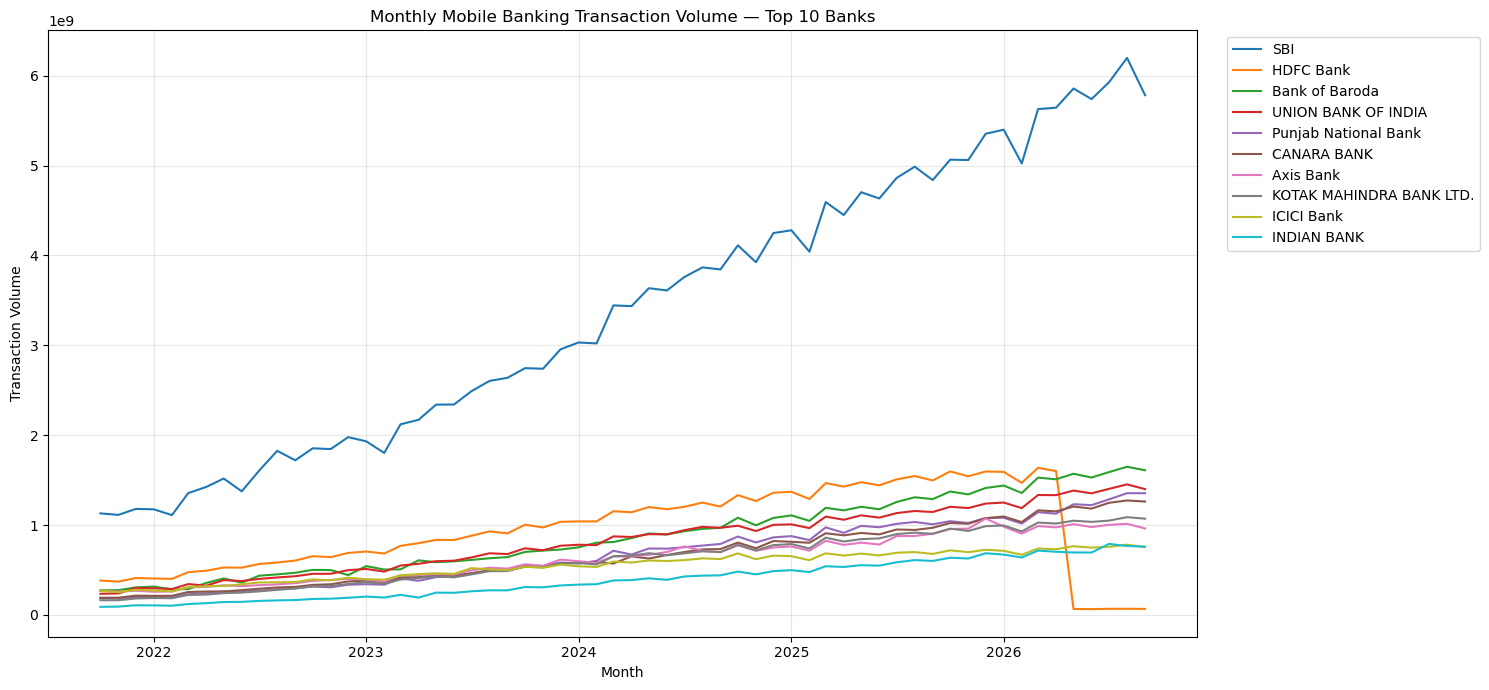

In [39]:
top_10_banks = mb_summary.head(10)['Bank Name']

# Plot monthly transaction trends
plt.figure(figsize=(15, 7))

for bank in top_10_banks:

    bank_data = monthly_mb_volume[
        monthly_mb_volume['Bank Name'] == bank
    ]

    plt.plot(
        bank_data['Date'],
        bank_data['Transaction_Volume'],
        label=bank,
        linewidth=1.5
    )

plt.title('Monthly Mobile Banking Transaction Volume — Top 10 Banks')
plt.xlabel('Month')
plt.ylabel('Transaction Volume')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### AQ-019 -- How did monthly Mobile Banking transaction value change by bank over the available period?

In [146]:
# Calculate monthly transaction value by bank
monthly_mb_value = (
    df_mb.groupby(['Bank Name', 'Date'])
    .agg(
        Transaction_Value=('Transaction Amount (₹ crore)', 'sum')
    )
    .reset_index()
    .sort_values(['Bank Name', 'Date'])
)

# Create bank-level summary
mb_value_summary = (
    monthly_mb_value.groupby('Bank Name')
    .agg(
        Total_Transaction_Value=('Transaction_Value', 'sum'),
        Average_Monthly_Value=('Transaction_Value', 'mean'),
        Highest_Monthly_Value=('Transaction_Value', 'max'),
        Lowest_Monthly_Value=('Transaction_Value', 'min'),
        Observed_Months=('Date', 'nunique')
    )
    .reset_index()
    .sort_values('Total_Transaction_Value', ascending=False)
)

# Display complete summary
pd.set_option('display.float_format', '{:,.2f}'.format)
mb_value_summary.round(2).head(10)

,Bank Name,Total_Transaction_Value,Average_Monthly_Value,Highest_Monthly_Value,Lowest_Monthly_Value,Observed_Months
585,SBI,"38,482,982.17","641,383.04","990,256.93","302,682.01",60
218,HDFC Bank,"20,161,558.01","336,025.97","567,227.13","163,131.46",60
228,ICICI Bank,"17,832,467.89","297,207.80","462,401.32","144,253.77",60
58,Axis Bank,"11,575,852.54","192,930.88","290,704.56","96,267.58",60
112,Bank of Baroda,"8,791,087.71","146,518.13","228,688.67","59,614.20",60
1109,UNION BANK OF INDIA,"8,386,076.42","139,767.94","204,544.14","53,334.88",60
118,CANARA BANK,"8,114,303.08","135,238.38","210,523.19","44,377.67",60
342,KOTAK MAHINDRA BANK LTD.,"7,968,891.62","132,814.86","220,102.26","59,628.37",60
508,Punjab National Bank,"6,426,709.57","107,111.83","178,047.72","39,545.70",60
246,INDUSIND BANK LTD.,"3,967,278.82","66,121.31","102,618.26","18,158.23",60


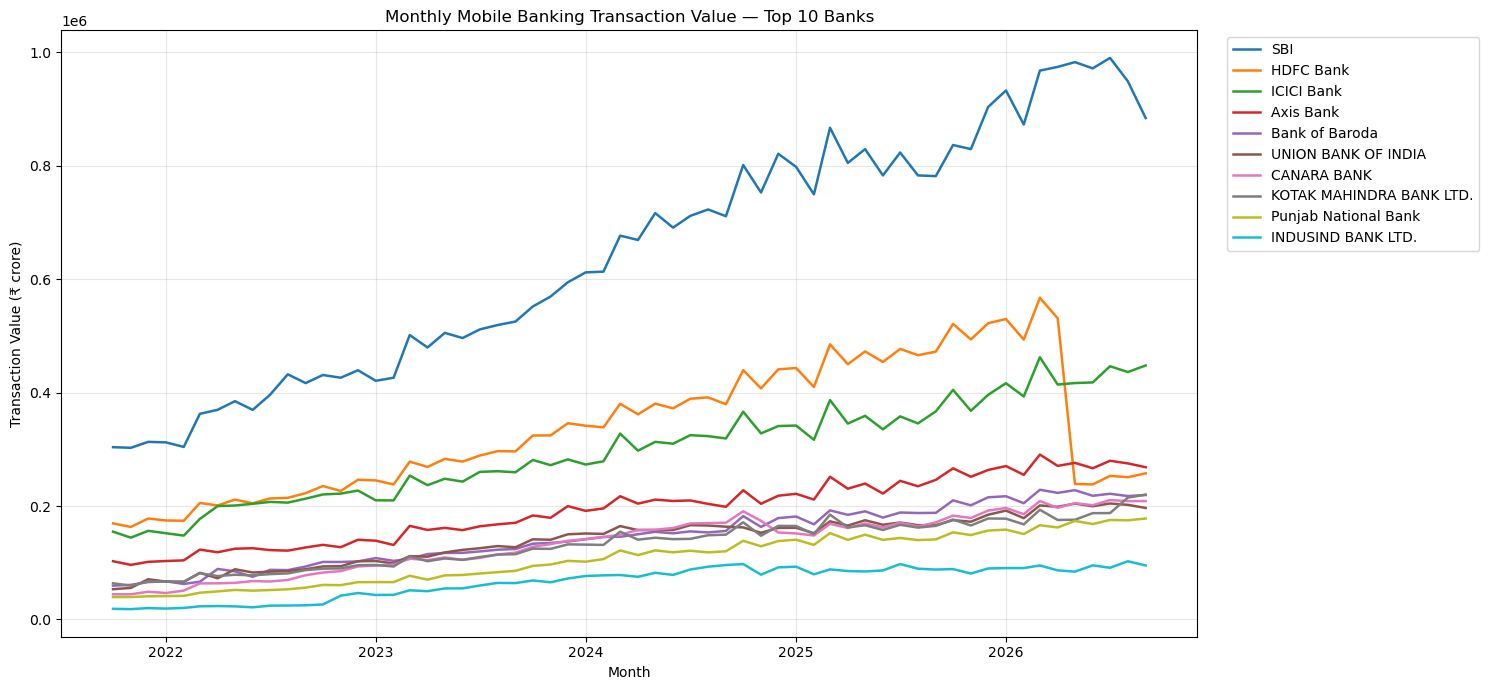

In [48]:
# Select top 10 banks by cumulative transaction value
top_10_value_banks = mb_value_summary.head(10)['Bank Name']

# Plot monthly transaction value trends
plt.figure(figsize=(15, 7))

for bank in top_10_value_banks:

    bank_data = monthly_mb_value[
        monthly_mb_value['Bank Name'] == bank
    ]

    plt.plot(
        bank_data['Date'],
        bank_data['Transaction_Value'],
        label=bank,
        linewidth=1.8
    )

plt.title('Monthly Mobile Banking Transaction Value — Top 10 Banks')
plt.xlabel('Month')
plt.ylabel('Transaction Value (₹ crore)')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### AQ-020 -- What same-month year-on-year changes are visible in Mobile Banking volume and value for banks with matched observations?

In [144]:
current_mb = df_mb[
    ['Bank Name', 'Date', 'Transaction Volume', 'Transaction Amount (₹ crore)']
].copy()

previous_mb = current_mb.copy()
previous_mb['Date'] = previous_mb['Date'] + pd.DateOffset(years=1)

previous_mb = previous_mb.rename(columns={
    'Transaction Volume': 'Previous_Year_Volume',
    'Transaction Amount (₹ crore)': 'Previous_Year_Value'
})

yoy_mb = current_mb.merge(
    previous_mb,
    on=['Bank Name', 'Date'],
    how='inner'
)

yoy_mb['Volume_Change'] = (
    yoy_mb['Transaction Volume'] - yoy_mb['Previous_Year_Volume']
)

yoy_mb['Value_Change'] = (
    yoy_mb['Transaction Amount (₹ crore)'] - yoy_mb['Previous_Year_Value']
)

mb_yoy_summary = (
    yoy_mb.groupby('Bank Name')
    .agg(
        Matched_Months=('Date', 'nunique'),
        Current_Volume=('Transaction Volume', 'sum'),
        Previous_Volume=('Previous_Year_Volume', 'sum'),
        Current_Value=('Transaction Amount (₹ crore)', 'sum'),
        Previous_Value=('Previous_Year_Value', 'sum')
    )
    .reset_index()
)

mb_yoy_summary['Volume_Change_%'] = (
    (mb_yoy_summary['Current_Volume'] - mb_yoy_summary['Previous_Volume'])
    / mb_yoy_summary['Previous_Volume'].replace(0, np.nan) * 100
)

mb_yoy_summary['Value_Change_%'] = (
    (mb_yoy_summary['Current_Value'] - mb_yoy_summary['Previous_Value'])
    / mb_yoy_summary['Previous_Value'].replace(0, np.nan) * 100
)

mb_yoy_summary = mb_yoy_summary.sort_values(
    'Current_Volume', ascending=False
)
pd.set_option('display.float_format', '{:,.2f}'.format)
mb_yoy_summary.round(2).head(10)

,Bank Name,Matched_Months,Current_Volume,Previous_Volume,Current_Value,Previous_Value,Volume_Change_%,Value_Change_%
506,SBI,48,"186,559,880,165.00","136,418,023,951.00","34,214,896.05","27,387,400.87",36.76,24.93
186,HDFC Bank,48,"51,117,688,501.00","45,499,031,541.00","17,829,215.39","15,264,163.05",12.35,16.80
98,Bank of Baroda,48,"48,521,947,995.00","34,835,708,452.00","7,891,250.45","6,185,538.04",39.29,27.58
919,UNION BANK OF INDIA,48,"45,368,236,411.00","33,681,387,985.00","7,488,873.49","6,076,377.06",34.70,23.25
438,Punjab National Bank,48,"37,887,409,943.00","26,743,534,037.00","5,863,256.34","4,459,746.64",41.67,31.47
100,CANARA BANK,48,"36,666,938,432.00","25,921,459,413.00","7,405,026.43","5,738,000.95",41.45,29.05
50,Axis Bank,48,"34,391,809,165.43","26,197,378,620.43","10,205,470.11","8,340,773.73",31.28,22.36
290,KOTAK MAHINDRA BANK LTD.,48,"34,350,933,504.00","24,870,004,596.00","7,082,024.33","5,748,721.38",38.12,23.19
196,ICICI Bank,48,"29,064,576,973.00","23,980,953,183.00","15,668,708.24","12,811,495.07",21.20,22.30
202,INDIAN BANK,48,"21,938,882,416.00","15,077,107,744.00","3,334,177.37","2,444,343.15",45.51,36.40


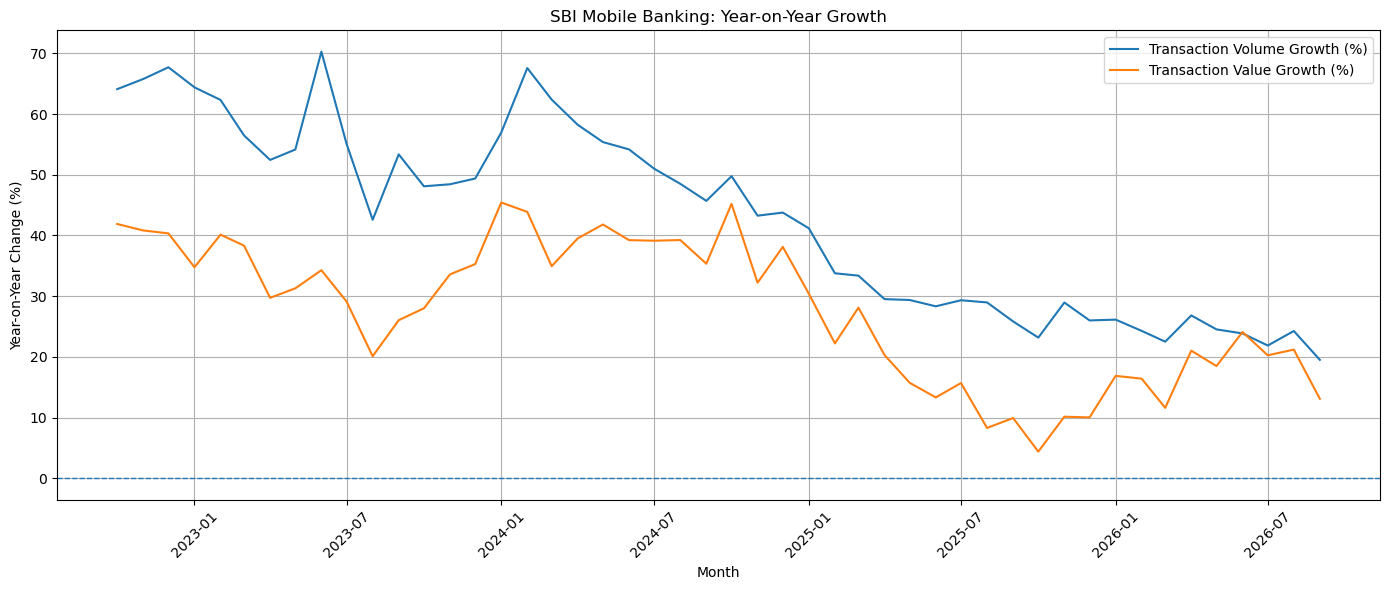

In [71]:
sbi_yoy = yoy_mb[
    yoy_mb['Bank Name'] == 'SBI'
].sort_values('Date').copy()

sbi_yoy['Volume_Growth_%'] = (
    sbi_yoy['Volume_Change']
    / sbi_yoy['Previous_Year_Volume'].replace(0, np.nan)
) * 100

sbi_yoy['Value_Growth_%'] = (
    sbi_yoy['Value_Change']
    / sbi_yoy['Previous_Year_Value'].replace(0, np.nan)
) * 100

plt.figure(figsize=(14, 6))

plt.plot(
    sbi_yoy['Date'],
    sbi_yoy['Volume_Growth_%'],
    label='Transaction Volume Growth (%)'
)

plt.plot(
    sbi_yoy['Date'],
    sbi_yoy['Value_Growth_%'],
    label='Transaction Value Growth (%)'
)

plt.axhline(0, linestyle='--', linewidth=1)

plt.title('SBI Mobile Banking: Year-on-Year Growth')
plt.xlabel('Month')
plt.ylabel('Year-on-Year Change (%)')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### AQ-021 -- How did reported Mobile Banking Active Customers change across observed bank-months?

In [142]:
monthly_mb_customers = (
    df_mb.dropna(subset=['Active Customers'])
    [['Bank Name', 'Date', 'Active Customers']]
    .sort_values(['Bank Name', 'Date'])
)

mb_customer_summary = (
    monthly_mb_customers.groupby('Bank Name')
    .agg(
        Average_Active_Customers=('Active Customers', 'mean'),
        Median_Active_Customers=('Active Customers', 'median'),
        Highest_Active_Customers=('Active Customers', 'max'),
        Lowest_Active_Customers=('Active Customers', 'min'),
        Observed_Months=('Date', 'nunique')
    )
    .reset_index()
    .sort_values('Average_Active_Customers', ascending=False)
)
pd.set_option('display.float_format', '{:,.2f}'.format)
mb_customer_summary.round(2).head(10)

,Bank Name,Average_Active_Customers,Median_Active_Customers,Highest_Active_Customers,Lowest_Active_Customers,Observed_Months
580,SBI,"126,251,066.33","128,508,300.00","168,821,591.00","84,455,157.00",55
217,HDFC Bank,"18,016,271.36","18,258,228.00","21,495,804.00","12,483,865.00",55
21,AIRTEL PAYMENTS BANK LTD.,"17,953,068.08","17,983,185.00","18,445,191.00","17,405,841.00",13
227,ICICI Bank,"15,968,967.35","16,612,872.00","17,549,269.00","8,056,099.00",55
56,Airtel Payments Bank,"13,356,910.29","14,274,296.50","20,200,182.00","5,825,485.00",42
339,KOTAK MAHINDRA BANK LTD.,"13,349,743.00","14,257,646.00","17,760,686.00","4,967,167.00",55
1102,UNION BANK OF INDIA,"8,849,458.04","2,911,875.00","22,504,992.00","1,216,806.00",55
469,PAYTM PAYMENTS BANK LIMITED,"6,980,140.65","11,141,874.00","15,123,246.00","82,853.00",49
190,FINO PAYMENTS BANK LIMITED,"5,862,607.69","5,740,028.00","7,184,476.00","5,002,351.00",13
58,Axis Bank,"4,678,828.60","4,734,170.00","5,203,406.00","4,121,848.00",55


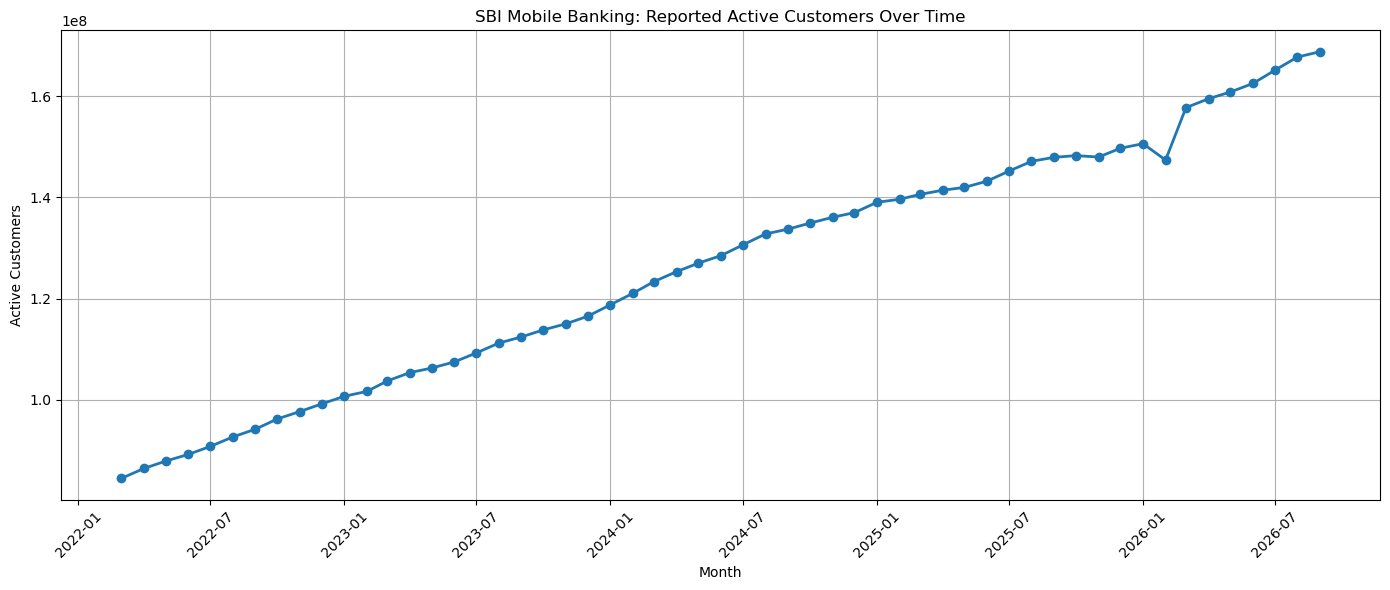

In [75]:
sbi_customers = monthly_mb_customers[
    monthly_mb_customers['Bank Name'] == 'SBI'
].sort_values('Date')

plt.figure(figsize=(14, 6))

plt.plot(
    sbi_customers['Date'],
    sbi_customers['Active Customers'],
    marker='o',
    linewidth=2
)

plt.title('SBI Mobile Banking: Reported Active Customers Over Time')
plt.xlabel('Month')
plt.ylabel('Active Customers')
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### AQ-022 -- What are the October–September annual Mobile Banking volume and value summaries by bank, where a full period is observed?

In [140]:
df_mb['Period_Start_Year'] = np.where(
    df_mb['Month'] >= 10,
    df_mb['Year'],
    df_mb['Year'] - 1
)

df_mb['Period'] = (
    df_mb['Period_Start_Year'].astype(str)
    + '-'
    + (df_mb['Period_Start_Year'] + 1).astype(str)
)

mb_annual = (
    df_mb.groupby(['Bank Name', 'Period', 'Period_Start_Year'])
    .agg(
        Transaction_Volume=('Transaction Volume', 'sum'),
        Transaction_Value=('Transaction Amount (₹ crore)', 'sum'),
        Observed_Months=('Date', 'nunique')
    )
    .reset_index()
)

mb_annual_complete = (
    mb_annual[mb_annual['Observed_Months'] == 12]
    .sort_values(['Bank Name', 'Period_Start_Year'])
    .drop(columns='Period_Start_Year')
)
pd.set_option('display.float_format', '{:,.2f}'.format)
mb_annual_complete.round(2).head(10)

,Bank Name,Period,Transaction_Volume,Transaction_Value,Observed_Months
0,A P MAHESH CO-OP URBAN BANK LTD,2021-2022,"123,456.00",442.10,12
1,A P MAHESH CO-OP URBAN BANK LTD,2022-2023,"140,071.00",519.43,12
2,A P MAHESH CO-OP URBAN BANK LTD,2023-2024,"154,288.00",567.88,12
5,A.P.VARDHAMAN(MAHILA) CO-OP.URBAN BK,2025-2026,"2,063,940.00",693.85,12
7,"A/C.GENERALS'OFF.CO-OP.BANK,BANGALORE",2025-2026,"133,749.00",68.90,12
8,"ABHINANDAN URBAN CO-OP BANK LTD., AMRAVATI",2021-2022,"20,726.00",76.52,12
9,"ABHINANDAN URBAN CO-OP BANK LTD., AMRAVATI",2022-2023,"20,928.00",101.32,12
10,"ABHINANDAN URBAN CO-OP BANK LTD., AMRAVATI",2023-2024,"121,606.00",176.47,12
13,ABHINANDAN URBAN CO-OP.BK.LTD.AMARAVATI,2025-2026,"971,467.00",442.88,12
14,"ABHINAV SAHAKARI BANK LTD, DOMBIVALI",2021-2022,"90,436.00",165.54,12


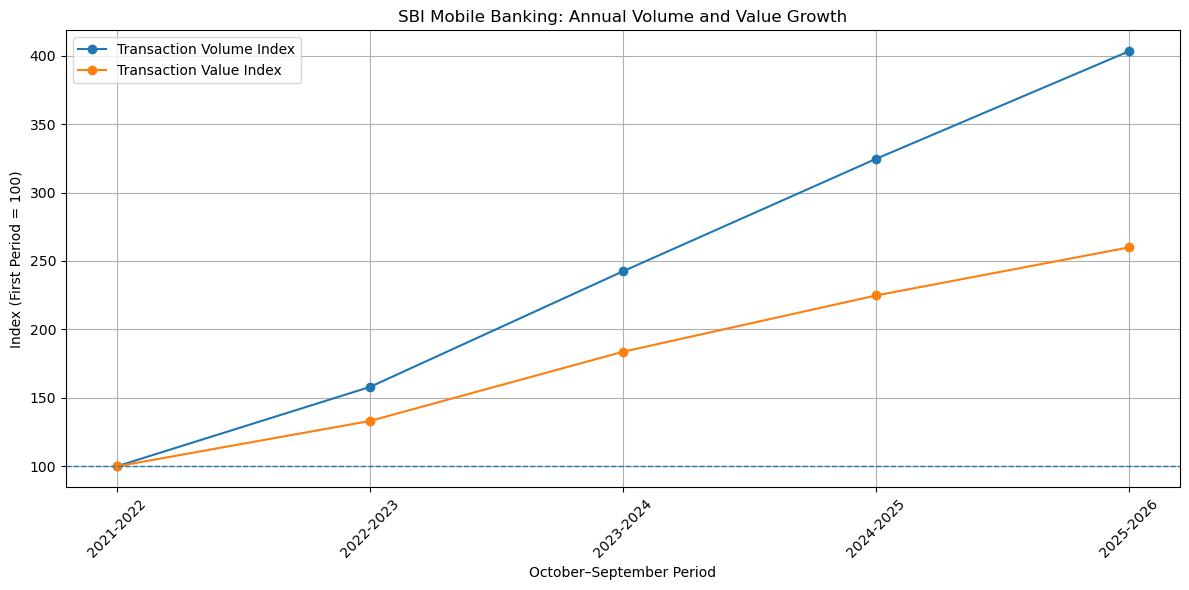

In [79]:
sbi_annual = mb_annual_complete[
    mb_annual_complete['Bank Name'] == 'SBI'
].sort_values('Period')

sbi_annual = sbi_annual.copy()

sbi_annual['Volume_Index'] = (
    sbi_annual['Transaction_Volume']
    / sbi_annual['Transaction_Volume'].iloc[0]
) * 100

sbi_annual['Value_Index'] = (
    sbi_annual['Transaction_Value']
    / sbi_annual['Transaction_Value'].iloc[0]
) * 100

plt.figure(figsize=(12, 6))

plt.plot(
    sbi_annual['Period'],
    sbi_annual['Volume_Index'],
    marker='o',
    label='Transaction Volume Index'
)

plt.plot(
    sbi_annual['Period'],
    sbi_annual['Value_Index'],
    marker='o',
    label='Transaction Value Index'
)

plt.axhline(100, linestyle='--', linewidth=1)

plt.title('SBI Mobile Banking: Annual Volume and Value Growth')
plt.xlabel('October–September Period')
plt.ylabel('Index (First Period = 100)')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### AQ-023 --How did monthly Internet Banking transaction volume change by bank over the available series?

In [138]:
df_ib['Date'] = pd.to_datetime(
    dict(year=df_ib['Year'], month=df_ib['Month'], day=1)
)

monthly_ib_volume = (
    df_ib.groupby(['Bank Name', 'Date'])
    .agg(Transaction_Volume=('Transaction Volume', 'sum'))
    .reset_index()
    .sort_values(['Bank Name', 'Date'])
)

ib_summary = (
    monthly_ib_volume.groupby('Bank Name')
    .agg(
        Total_Transactions=('Transaction_Volume', 'sum'),
        Average_Monthly_Transactions=('Transaction_Volume', 'mean'),
        Highest_Monthly_Transactions=('Transaction_Volume', 'max'),
        Lowest_Monthly_Transactions=('Transaction_Volume', 'min'),
        Observed_Months=('Date', 'nunique')
    )
    .reset_index()
    .sort_values('Total_Transactions', ascending=False)
)
pd.set_option('display.float_format', '{:,.2f}'.format)
ib_summary.round(2).head(10)

,Bank Name,Total_Transactions,Average_Monthly_Transactions,Highest_Monthly_Transactions,Lowest_Monthly_Transactions,Observed_Months
156,SBI,6506086711,"118,292,485.65",140802238,103119008,55
80,ICICI Bank,4865185971,"88,457,926.75",116176827,18550126,55
77,HDFC Bank,3211922739,"58,398,595.25",70264926,30715088,55
37,CENTRAL BANK OF INDIA,572771607,"10,414,029.22",14704922,8374149,55
114,Kotak Mahindra Bank,554849070,"13,210,692.14",16664115,11038469,42
79,HSBC,406307195,"9,673,980.83",14910142,6588623,42
144,Punjab National Bank,304892139,"5,543,493.44",6763518,4928575,55
18,Axis Bank,255239947,"4,640,726.31",6414594,3110607,55
224,YES BANK,249686789,"5,806,669.51",7803460,4746453,43
22,BANK OF MAHARASHTRA,249589785,"4,537,996.09",8275631,1048497,55


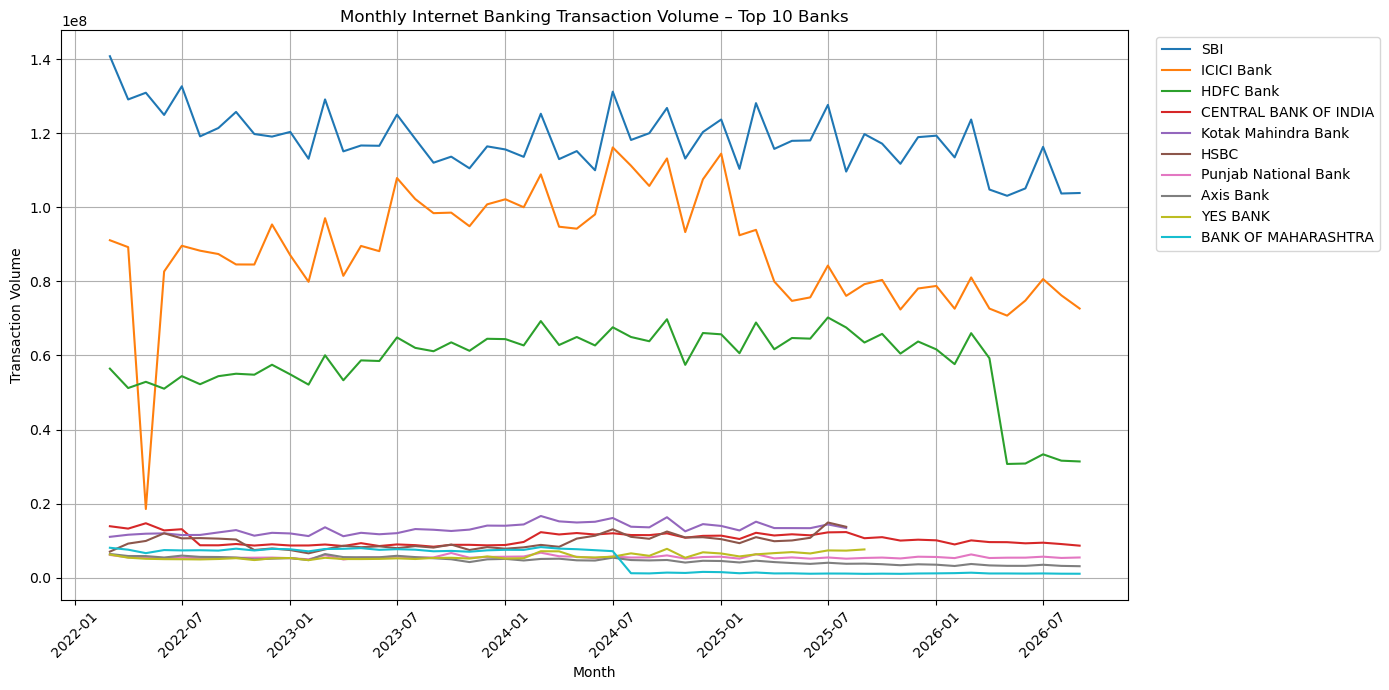

In [86]:
top_10_ib = ib_summary.head(10)['Bank Name']

ib_top_banks = monthly_ib_volume[
    monthly_ib_volume['Bank Name'].isin(top_10_ib)
]

plt.figure(figsize=(14, 7))

for bank in top_10_ib:
    bank_data = ib_top_banks[
        ib_top_banks['Bank Name'] == bank
    ]

    plt.plot(
        bank_data['Date'],
        bank_data['Transaction_Volume'],
        label=bank
    )

plt.title('Monthly Internet Banking Transaction Volume – Top 10 Banks')
plt.xlabel('Month')
plt.ylabel('Transaction Volume')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### AQ-024 -- How did monthly Internet Banking transaction value change by bank over the available period?

In [136]:
monthly_ib_value = (
    df_ib.groupby(['Bank Name', 'Date'])
    .agg(Transaction_Value=('Transaction Amount (₹ crore)', 'sum'))
    .reset_index()
    .sort_values(['Bank Name', 'Date'])
)

ib_value_summary = (
    monthly_ib_value.groupby('Bank Name')
    .agg(
        Total_Transaction_Value=('Transaction_Value', 'sum'),
        Average_Monthly_Value=('Transaction_Value', 'mean'),
        Highest_Monthly_Value=('Transaction_Value', 'max'),
        Lowest_Monthly_Value=('Transaction_Value', 'min'),
        Observed_Months=('Date', 'nunique')
    )
    .reset_index()
    .sort_values('Total_Transaction_Value', ascending=False)
)
pd.set_option('display.float_format', '{:,.2f}'.format)
ib_value_summary.round(2).head(10)

,Bank Name,Total_Transaction_Value,Average_Monthly_Value,Highest_Monthly_Value,Lowest_Monthly_Value,Observed_Months
80,ICICI Bank,"241,299,030.27","4,387,255.10","6,630,713.03","2,237,987.68",55
156,SBI,"117,605,033.83","2,138,273.34","3,448,815.57","1,283,664.39",55
77,HDFC Bank,"32,965,958.18","599,381.06","895,897.72","388,736.42",55
79,HSBC,"18,728,957.11","445,927.55","676,098.16","306,128.97",42
54,DEUTSCHE BANK AG,"17,355,926.52","1,335,071.27","1,548,656.87","1,095,136.79",13
58,Deutsche Bank,"16,891,485.52","402,178.23","1,260,622.76",292.56,42
114,Kotak Mahindra Bank,"14,806,592.69","352,537.92","505,955.84","247,346.25",42
187,THE HONGKONG AND SHANGHAI BANKING CORPORATION ...,"11,645,052.54","895,773.27","1,172,186.25","687,331.99",13
144,Punjab National Bank,"9,848,899.39","179,070.90","263,598.40","134,400.74",55
224,YES BANK,"8,850,702.30","205,830.29","309,488.92","143,741.99",43


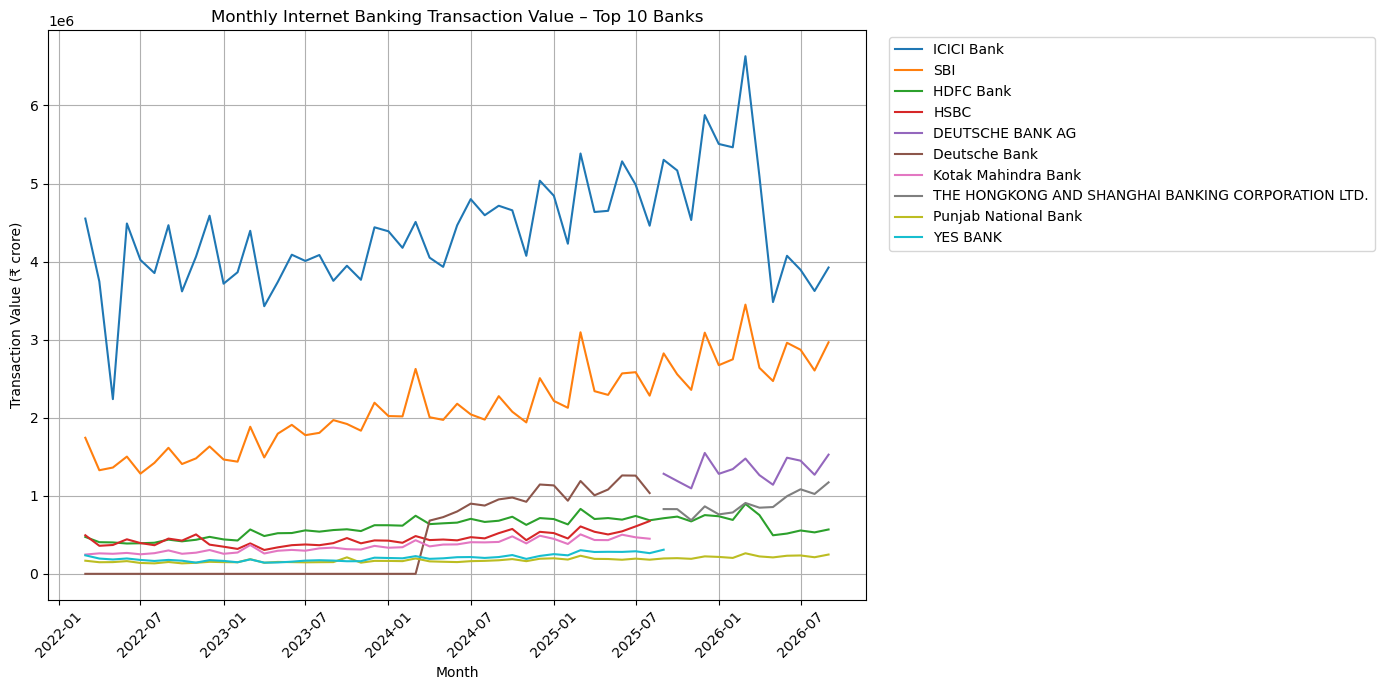

In [91]:
top_10_ib_value = ib_value_summary.head(10)['Bank Name']

ib_top_value_banks = monthly_ib_value[
    monthly_ib_value['Bank Name'].isin(top_10_ib_value)
]

plt.figure(figsize=(14, 7))

for bank in top_10_ib_value:
    bank_data = ib_top_value_banks[
        ib_top_value_banks['Bank Name'] == bank
    ]

    plt.plot(
        bank_data['Date'],
        bank_data['Transaction_Value'],
        label=bank
    )

plt.title('Monthly Internet Banking Transaction Value – Top 10 Banks')
plt.xlabel('Month')
plt.ylabel('Transaction Value (₹ crore)')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### AQ-025 -- What same-month year-on-year changes are visible in Internet Banking volume and value for banks with matched observations?

In [134]:
current_ib = df_ib[
    ['Bank Name', 'Date', 'Transaction Volume', 'Transaction Amount (₹ crore)']
].copy()

previous_ib = current_ib.copy()
previous_ib['Date'] = previous_ib['Date'] + pd.DateOffset(years=1)

previous_ib = previous_ib.rename(columns={
    'Transaction Volume': 'Previous_Year_Volume',
    'Transaction Amount (₹ crore)': 'Previous_Year_Value'
})

yoy_ib = current_ib.merge(
    previous_ib,
    on=['Bank Name', 'Date'],
    how='inner'
)

yoy_ib['Volume_Change'] = (
    yoy_ib['Transaction Volume'] - yoy_ib['Previous_Year_Volume']
)

yoy_ib['Value_Change'] = (
    yoy_ib['Transaction Amount (₹ crore)'] - yoy_ib['Previous_Year_Value']
)

ib_yoy_summary = (
    yoy_ib.groupby('Bank Name')
    .agg(
        Matched_Months=('Date', 'nunique'),
        Current_Volume=('Transaction Volume', 'sum'),
        Previous_Volume=('Previous_Year_Volume', 'sum'),
        Current_Value=('Transaction Amount (₹ crore)', 'sum'),
        Previous_Value=('Previous_Year_Value', 'sum')
    )
    .reset_index()
)

ib_yoy_summary['Volume_Change_%'] = (
    (ib_yoy_summary['Current_Volume'] - ib_yoy_summary['Previous_Volume'])
    / ib_yoy_summary['Previous_Volume'].replace(0, np.nan) * 100
)

ib_yoy_summary['Value_Change_%'] = (
    (ib_yoy_summary['Current_Value'] - ib_yoy_summary['Previous_Value'])
    / ib_yoy_summary['Previous_Value'].replace(0, np.nan) * 100
)

ib_yoy_summary = ib_yoy_summary.sort_values(
    'Current_Volume', ascending=False
)
pd.set_option('display.float_format', '{:,.2f}'.format)
ib_yoy_summary.round(2).head(10)

,Bank Name,Matched_Months,Current_Volume,Previous_Volume,Current_Value,Previous_Value,Volume_Change_%,Value_Change_%
133,SBI,43,5008859833,5164677232,"99,929,378.66","84,222,257.96",-3.02,18.65
68,ICICI Bank,43,3886801918,3953980506,"194,085,808.43","184,031,501.65",-1.70,5.46
65,HDFC Bank,43,2564815315,2619355129,"27,870,388.70","25,063,832.23",-2.08,11.20
31,CENTRAL BANK OF INDIA,43,443296783,456643019,"1,298,133.84","1,137,469.86",-2.92,14.12
97,Kotak Mahindra Bank,30,413515658,388048185,"11,590,534.42","9,415,308.92",6.56,23.10
67,HSBC,30,296473837,271467976,"13,876,020.19","12,206,348.72",9.21,13.68
123,Punjab National Bank,43,239813700,238739753,"8,062,022.29","7,183,359.11",0.45,12.23
74,INDUSIND BANK LTD.,43,203603464,198266227,"1,732,080.76","1,993,890.81",2.69,-13.13
13,Axis Bank,43,188855318,214643764,"1,949,884.05","1,855,076.96",-12.01,5.11
187,YES BANK,31,187543759,168573635,"6,709,986.86","5,687,135.70",11.25,17.99


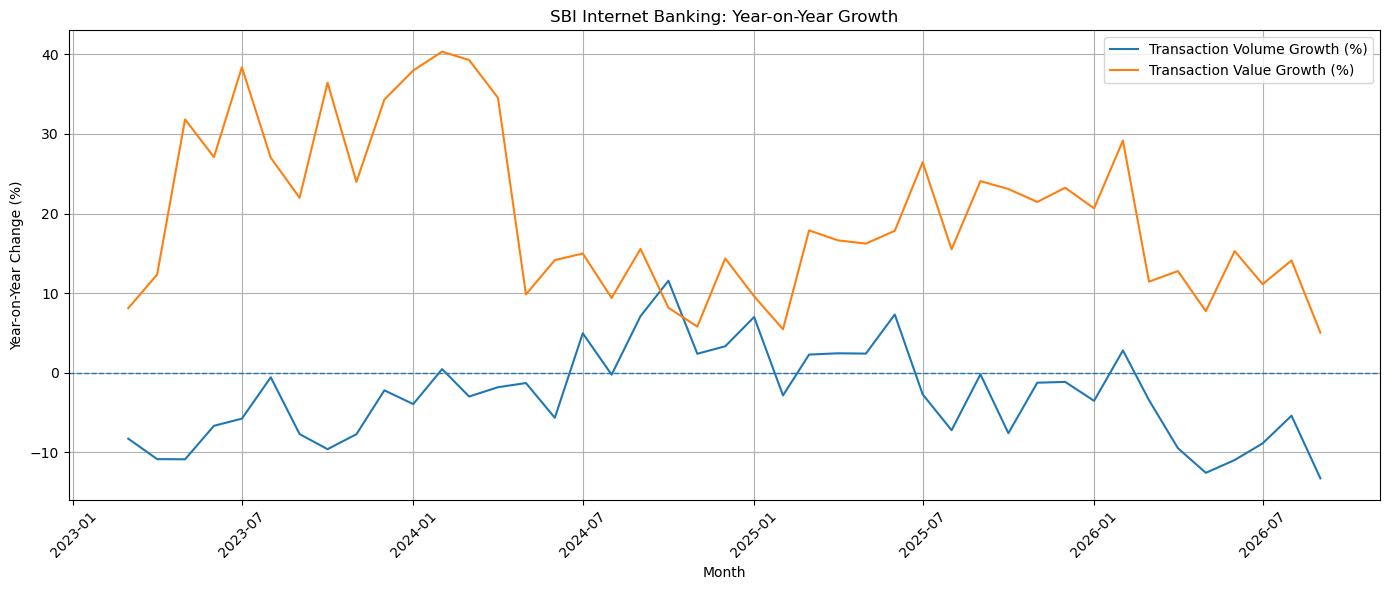

In [96]:
sbi_ib_yoy = yoy_ib[
    yoy_ib['Bank Name'] == 'SBI'
].sort_values('Date').copy()

sbi_ib_yoy['Volume_Growth_%'] = (
    sbi_ib_yoy['Volume_Change']
    / sbi_ib_yoy['Previous_Year_Volume'].replace(0, np.nan)
) * 100

sbi_ib_yoy['Value_Growth_%'] = (
    sbi_ib_yoy['Value_Change']
    / sbi_ib_yoy['Previous_Year_Value'].replace(0, np.nan)
) * 100

plt.figure(figsize=(14, 6))

plt.plot(
    sbi_ib_yoy['Date'],
    sbi_ib_yoy['Volume_Growth_%'],
    label='Transaction Volume Growth (%)'
)

plt.plot(
    sbi_ib_yoy['Date'],
    sbi_ib_yoy['Value_Growth_%'],
    label='Transaction Value Growth (%)'
)

plt.axhline(0, linestyle='--', linewidth=1)

plt.title('SBI Internet Banking: Year-on-Year Growth')
plt.xlabel('Month')
plt.ylabel('Year-on-Year Change (%)')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### AQ-026 -- How did reported Internet Banking Active Customers change across observed bank-months?

In [99]:
monthly_ib_customers = (
    df_ib.dropna(subset=['Active Customers'])
    [['Bank Name', 'Date', 'Active Customers']]
    .sort_values(['Bank Name', 'Date'])
)

ib_customer_summary = (
    monthly_ib_customers.groupby('Bank Name')
    .agg(
        Average_Active_Customers=('Active Customers', 'mean'),
        Median_Active_Customers=('Active Customers', 'median'),
        Highest_Active_Customers=('Active Customers', 'max'),
        Lowest_Active_Customers=('Active Customers', 'min'),
        Observed_Months=('Date', 'nunique')
    )
    .reset_index()
    .sort_values('Average_Active_Customers', ascending=False)
)

ib_customer_summary.round(2).head(10)

,Bank Name,Average_Active_Customers,Median_Active_Customers,Highest_Active_Customers,Lowest_Active_Customers,Observed_Months
156,SBI,37568766.69,38291274.0,43611814.0,24237143.0,55
77,HDFC Bank,25888309.31,27763663.0,31580089.0,6339207.0,55
80,ICICI Bank,4132947.60,4196250.0,4620532.0,3015657.0,55
114,Kotak Mahindra Bank,1992636.69,1992015.5,2212445.0,1755725.0,42
18,Axis Bank,1423914.64,1360750.0,3101982.0,983292.0,55
111,KOTAK MAHINDRA BANK LTD.,939303.00,563611.0,1921722.0,447797.0,13
84,INDIAN BANK,731171.91,436217.0,1351244.0,261285.0,55
144,Punjab National Bank,632436.45,617092.0,852226.0,538761.0,55
81,IDBI BANK,547536.00,543145.0,627795.0,467643.0,42
49,Citibank,543418.58,545639.0,572887.0,501400.0,12


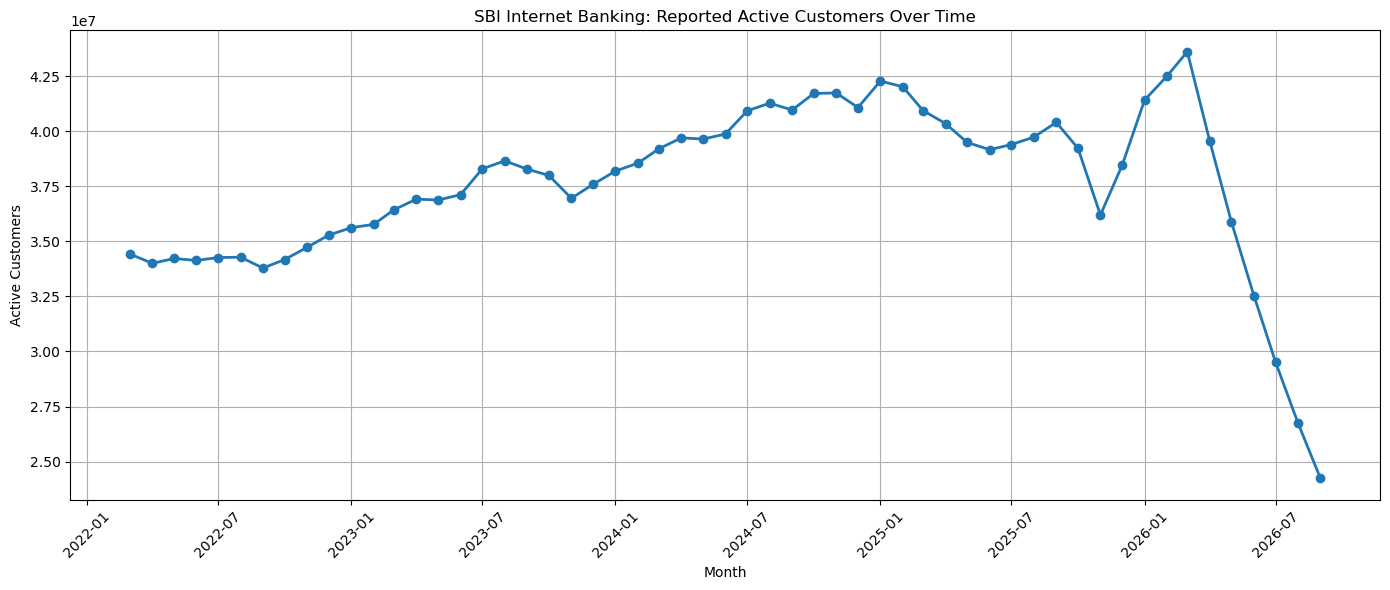

In [101]:
sbi_ib_customers = monthly_ib_customers[
    monthly_ib_customers['Bank Name'] == 'SBI'
].sort_values('Date')

plt.figure(figsize=(14, 6))

plt.plot(
    sbi_ib_customers['Date'],
    sbi_ib_customers['Active Customers'],
    marker='o',
    linewidth=2
)

plt.title('SBI Internet Banking: Reported Active Customers Over Time')
plt.xlabel('Month')
plt.ylabel('Active Customers')
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### AQ-027 -- What are the October–September annual Internet Banking volume and value summaries by bank for fully covered periods?

In [132]:
df_ib['Period_Start_Year'] = np.where(
    df_ib['Month'] >= 10,
    df_ib['Year'],
    df_ib['Year'] - 1
)

df_ib['Period'] = (
    df_ib['Period_Start_Year'].astype(str)
    + '-'
    + (df_ib['Period_Start_Year'] + 1).astype(str)
)

ib_annual = (
    df_ib.groupby(['Bank Name', 'Period', 'Period_Start_Year'])
    .agg(
        Transaction_Volume=('Transaction Volume', 'sum'),
        Transaction_Value=('Transaction Amount (₹ crore)', 'sum'),
        Observed_Months=('Date', 'nunique')
    )
    .reset_index()
)

ib_annual_complete = (
    ib_annual[ib_annual['Observed_Months'] == 12]
    .sort_values(['Bank Name', 'Period_Start_Year'])
    .drop(columns='Period_Start_Year')
)
pd.set_option('display.float_format', '{:,.2f}'.format)
ib_annual_complete.round(2).head(10)

,Bank Name,Period,Transaction_Volume,Transaction_Value,Observed_Months
1,"ABHYUDAYA CO-OP. BANK LTD., MUMBAI",2025-2026,10,0.03,12
3,ABHYUDAYA CO-OPERATIVE BANK LTD,2022-2023,21,0.04,12
4,ABHYUDAYA CO-OPERATIVE BANK LTD,2023-2024,38,0.24,12
7,AHMEDABAD MERCANTILE CO-OP.BANK LTD.,2025-2026,140624,"2,773.63",12
9,AHMEDNAGAR MERCHANTS CO-OP BANK LTD,2022-2023,260119,"4,354.57",12
10,AHMEDNAGAR MERCHANTS CO-OP BANK LTD,2023-2024,284065,"4,841.59",12
11,AHMEDNAGAR MERCHANTS CO-OP BANK LTD,2024-2025,306487,"5,287.16",12
12,AHMEDNAGAR MERCHANTS CO-OP BANK LTD,2025-2026,321120,"5,718.41",12
16,ANDHRA PRADESH GRAMEENA BANK,2025-2026,313552,"1,514.73",12
19,ANDHRA PRADESH GRAMEENA VIKAS BANK,2023-2024,19632,151.64,12


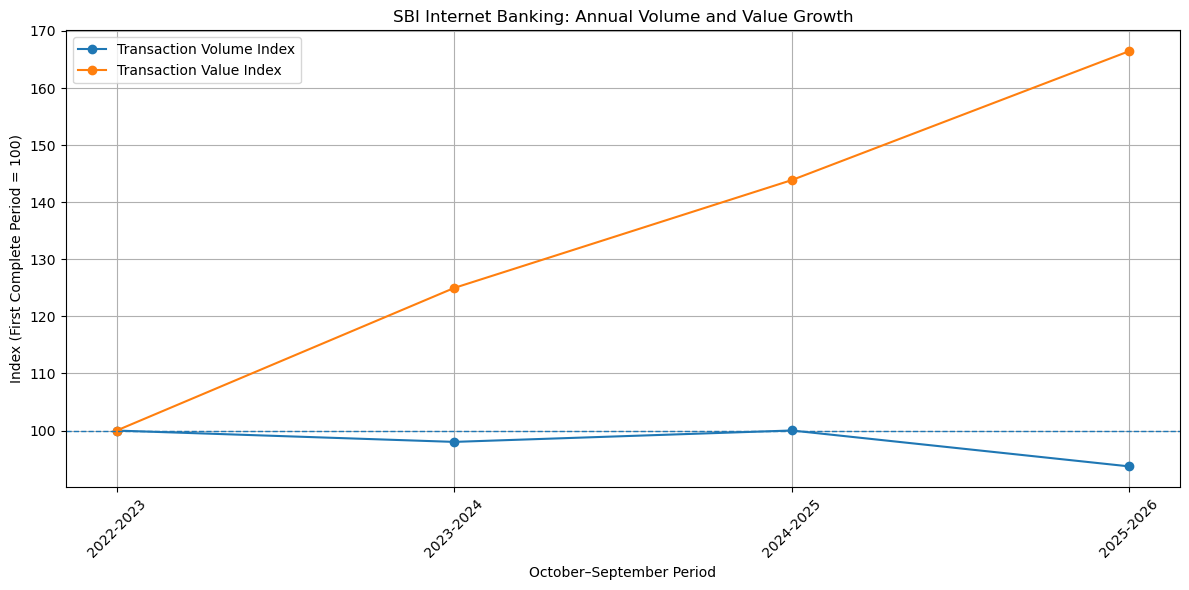

In [108]:
sbi_ib_annual = ib_annual_complete[
    ib_annual_complete['Bank Name'] == 'SBI'
].sort_values('Period').copy()

sbi_ib_annual['Volume_Index'] = (
    sbi_ib_annual['Transaction_Volume']
    / sbi_ib_annual['Transaction_Volume'].iloc[0]
) * 100

sbi_ib_annual['Value_Index'] = (
    sbi_ib_annual['Transaction_Value']
    / sbi_ib_annual['Transaction_Value'].iloc[0]
) * 100

plt.figure(figsize=(12, 6))

plt.plot(
    sbi_ib_annual['Period'],
    sbi_ib_annual['Volume_Index'],
    marker='o',
    label='Transaction Volume Index'
)

plt.plot(
    sbi_ib_annual['Period'],
    sbi_ib_annual['Value_Index'],
    marker='o',
    label='Transaction Value Index'
)

plt.axhline(100, linestyle='--', linewidth=1)

plt.title('SBI Internet Banking: Annual Volume and Value Growth')
plt.xlabel('October–September Period')
plt.ylabel('Index (First Complete Period = 100)')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### AQ-028 -- How did monthly inward and outward NEFT transaction volumes change by bank?

In [126]:
df_neft['Date'] = pd.to_datetime(
    dict(year=df_neft['Year'], month=df_neft['Month'], day=1)
)

monthly_neft_volume = (
    df_neft.groupby(['Bank Name', 'Date'])
    .agg(
        Inward_Volume=('Inward Volume', 'sum'),
        Outward_Volume=('Outward Volume', 'sum')
    )
    .reset_index()
    .sort_values(['Bank Name', 'Date'])
)

neft_volume_summary = (
    monthly_neft_volume.groupby('Bank Name')
    .agg(
        Total_Inward_Volume=('Inward_Volume', 'sum'),
        Total_Outward_Volume=('Outward_Volume', 'sum'),
        Average_Inward_Volume=('Inward_Volume', 'mean'),
        Average_Outward_Volume=('Outward_Volume', 'mean'),
        Observed_Months=('Date', 'nunique')
    )
    .reset_index()
    .sort_values('Total_Inward_Volume', ascending=False)
)
pd.set_option('display.float_format', '{:,.2f}'.format)
neft_volume_summary.round(2).head(10)

,Bank Name,Total_Inward_Volume,Total_Outward_Volume,Average_Inward_Volume,Average_Outward_Volume,Observed_Months
167,SBI,9497648728,1869721102,"158,294,145.47","31,162,018.37",60
71,HDFC Bank,3244816624,3252371995,"54,080,277.07","54,206,199.92",60
34,Bank of Baroda,3186312086,434817688,"53,105,201.43","7,246,961.47",60
147,Punjab National Bank,2862814468,450200201,"47,713,574.47","7,503,336.68",60
242,UNION BANK OF INDIA,2299183660,369504901,"38,319,727.67","6,158,415.02",60
75,ICICI Bank,1960423625,2822969036,"32,673,727.08","47,049,483.93",60
35,CANARA BANK,1922481906,407386330,"32,041,365.10","6,789,772.17",60
24,BANK OF INDIA,1480275575,186769107,"24,671,259.58","3,112,818.45",60
111,KOTAK MAHINDRA BANK LTD.,1407041567,692692906,"23,450,692.78","11,544,881.77",60
15,Axis Bank,1394889246,11518792059,"23,248,154.10","191,979,867.65",60


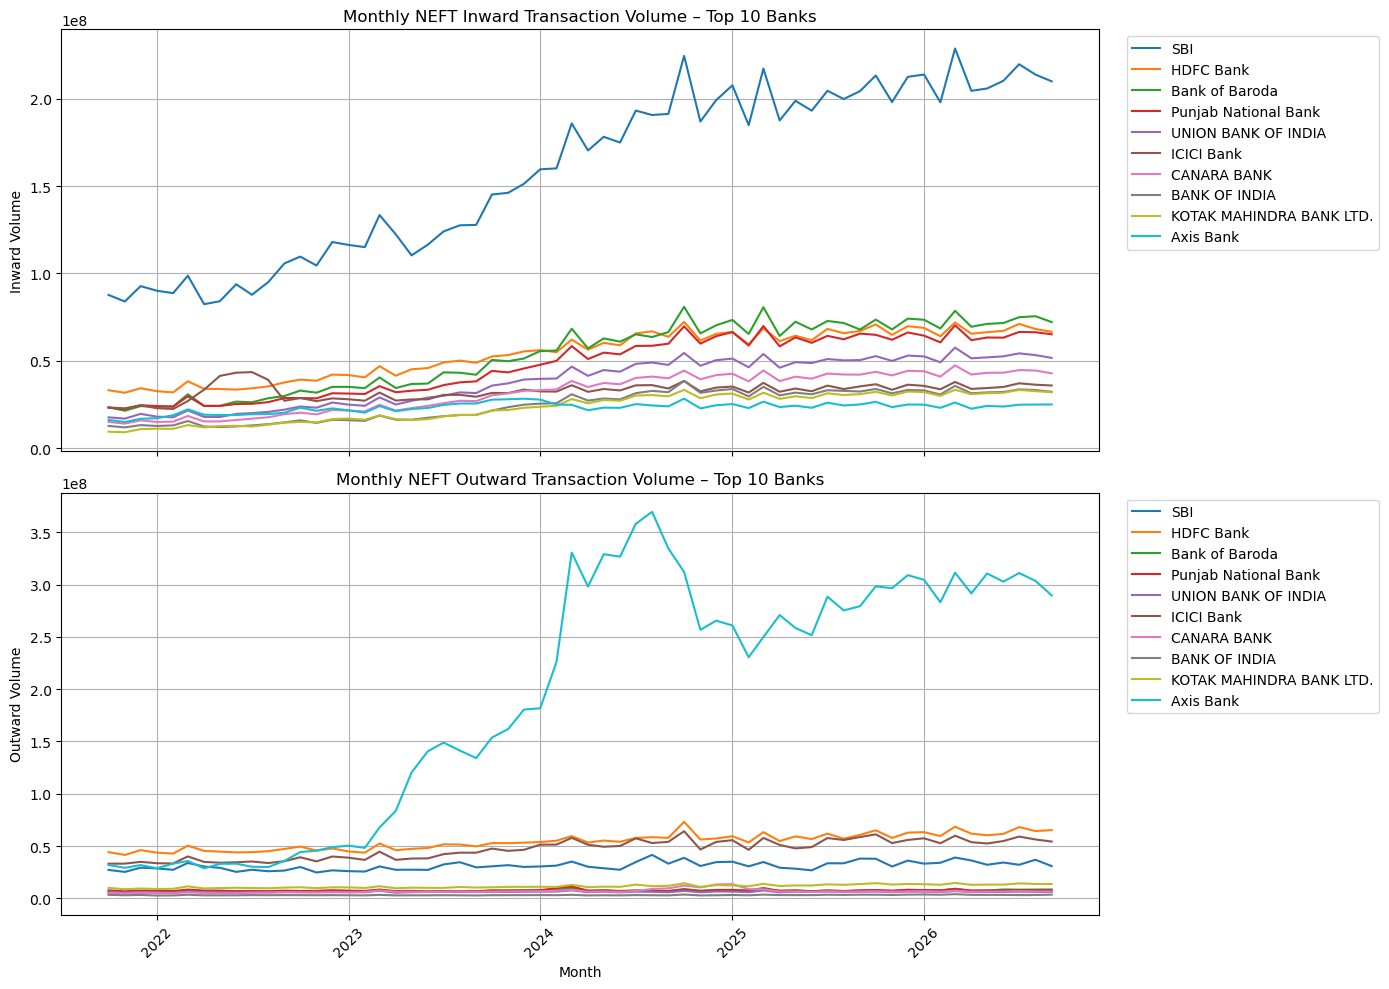

In [117]:
top_10_neft = neft_volume_summary.head(10)['Bank Name']

neft_top_banks = monthly_neft_volume[
    monthly_neft_volume['Bank Name'].isin(top_10_neft)
]

fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=True)

for bank in top_10_neft:
    bank_data = neft_top_banks[
        neft_top_banks['Bank Name'] == bank
    ]

    axes[0].plot(
        bank_data['Date'],
        bank_data['Inward_Volume'],
        label=bank
    )

    axes[1].plot(
        bank_data['Date'],
        bank_data['Outward_Volume'],
        label=bank
    )

axes[0].set_title('Monthly NEFT Inward Transaction Volume – Top 10 Banks')
axes[0].set_ylabel('Inward Volume')
axes[0].legend(bbox_to_anchor=(1.02, 1), loc='upper left')
axes[0].grid(True)

axes[1].set_title('Monthly NEFT Outward Transaction Volume – Top 10 Banks')
axes[1].set_xlabel('Month')
axes[1].set_ylabel('Outward Volume')
axes[1].legend(bbox_to_anchor=(1.02, 1), loc='upper left')
axes[1].grid(True)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### AQ-029 -- How did monthly inward and outward NEFT transaction values change by bank?

In [124]:
monthly_neft_value = (
    df_neft.groupby(['Bank Name', 'Date'])
    .agg(
        Inward_Value=('Inward Amount (₹ crore)', 'sum'),
        Outward_Value=('Outward Amount (₹ crore)', 'sum')
    )
    .reset_index()
    .sort_values(['Bank Name', 'Date'])
)

neft_value_summary = (
    monthly_neft_value.groupby('Bank Name')
    .agg(
        Total_Inward_Value=('Inward_Value', 'sum'),
        Total_Outward_Value=('Outward_Value', 'sum'),
        Average_Inward_Value=('Inward_Value', 'mean'),
        Average_Outward_Value=('Outward_Value', 'mean'),
        Observed_Months=('Date', 'nunique')
    )
    .reset_index()
)

neft_value_summary['Combined_Value'] = (
    neft_value_summary['Total_Inward_Value']
    + neft_value_summary['Total_Outward_Value']
)

neft_value_summary = neft_value_summary.sort_values(
    'Combined_Value', ascending=False
)
pd.set_option('display.float_format', '{:,.2f}'.format)
neft_value_summary.round(2).head(10)

,Bank Name,Total_Inward_Value,Total_Outward_Value,Average_Inward_Value,Average_Outward_Value,Observed_Months,Combined_Value
71,HDFC Bank,"33,102,311.92","25,088,280.71","551,705.20","418,138.01",60,"58,190,592.62"
167,SBI,"34,196,917.71","21,511,330.01","569,948.63","358,522.17",60,"55,708,247.72"
75,ICICI Bank,"20,356,070.88","19,129,960.01","339,267.85","318,832.67",60,"39,486,030.89"
15,Axis Bank,"18,075,912.76","20,508,951.08","301,265.21","341,815.85",60,"38,584,863.84"
156,"RBI,PAD","3,097,327.56","28,142,596.96","51,622.13","469,043.28",60,"31,239,924.52"
40,CITI BANK,"7,744,122.23","10,661,902.18","129,068.70","177,698.37",60,"18,406,024.41"
254,YES BANK,"4,925,218.38","12,150,434.63","82,086.97","202,507.24",60,"17,075,653.01"
111,KOTAK MAHINDRA BANK LTD.,"6,927,405.77","6,004,695.80","115,456.76","100,078.26",60,"12,932,101.57"
73,HSBC BANK,"5,511,554.59","6,833,823.96","91,859.24","113,897.07",60,"12,345,378.55"
147,Punjab National Bank,"7,216,689.03","3,612,562.72","120,278.15","60,209.38",60,"10,829,251.74"


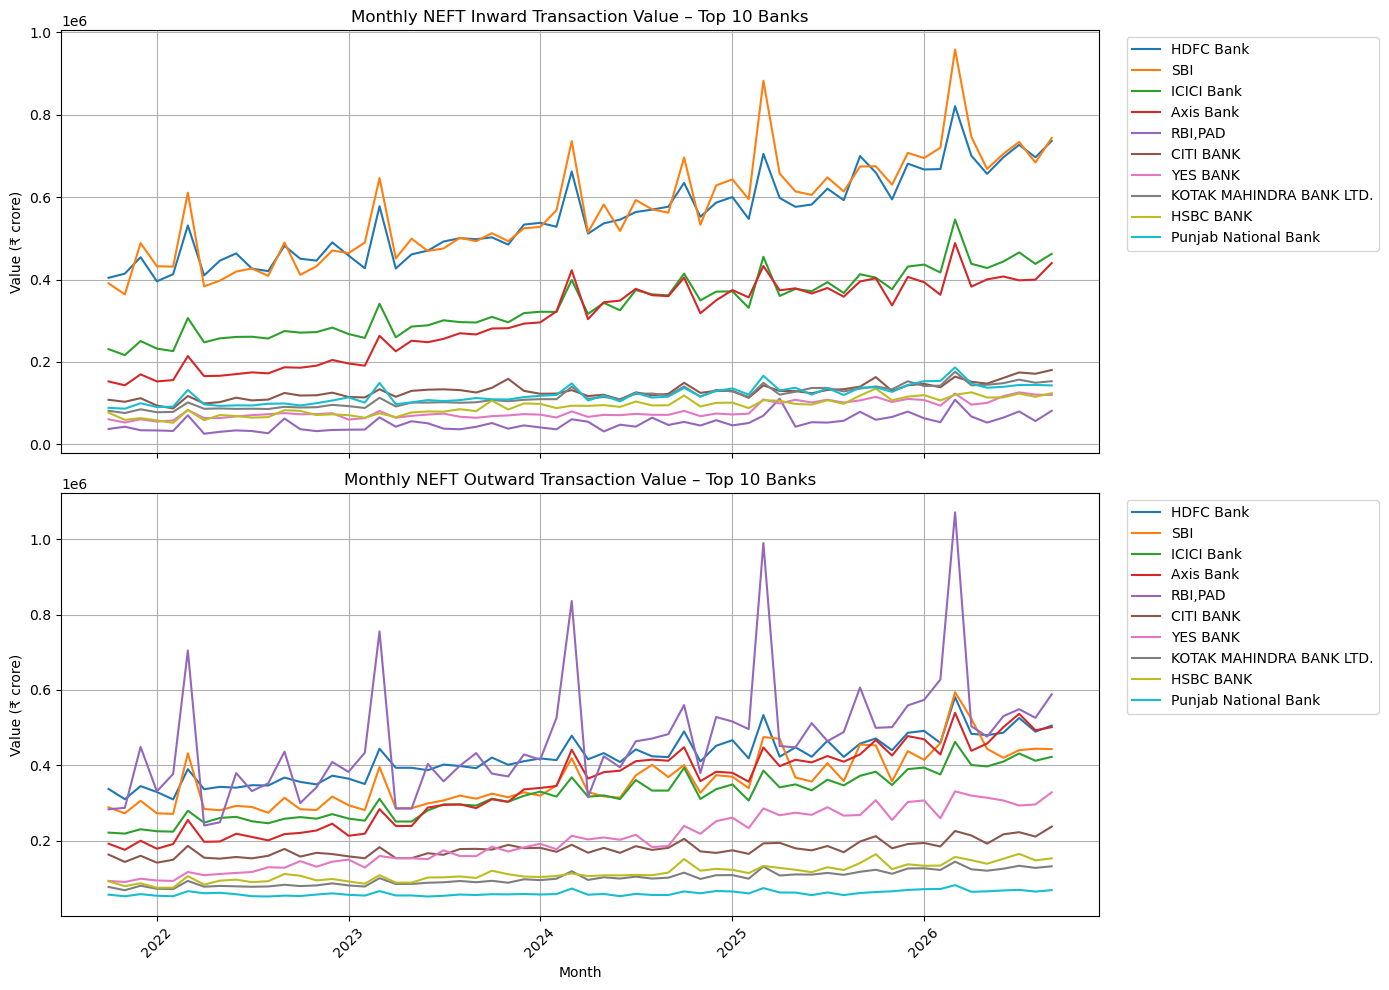

In [121]:
top_10_neft_value = neft_value_summary.head(10)['Bank Name']

neft_value_top_banks = monthly_neft_value[
    monthly_neft_value['Bank Name'].isin(top_10_neft_value)
]

fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=True)

for bank in top_10_neft_value:
    bank_data = neft_value_top_banks[
        neft_value_top_banks['Bank Name'] == bank
    ]

    axes[0].plot(
        bank_data['Date'],
        bank_data['Inward_Value'],
        label=bank
    )

    axes[1].plot(
        bank_data['Date'],
        bank_data['Outward_Value'],
        label=bank
    )

axes[0].set_title('Monthly NEFT Inward Transaction Value – Top 10 Banks')
axes[0].set_ylabel('Value (₹ crore)')
axes[0].legend(bbox_to_anchor=(1.02, 1), loc='upper left')
axes[0].grid(True)

axes[1].set_title('Monthly NEFT Outward Transaction Value – Top 10 Banks')
axes[1].set_xlabel('Month')
axes[1].set_ylabel('Value (₹ crore)')
axes[1].legend(bbox_to_anchor=(1.02, 1), loc='upper left')
axes[1].grid(True)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### AQ-030 -- Across matched reporting months, how did SBI’s inward and outward NEFT activity compare with participating banks?

In [203]:
sbi_neft = df_neft[
    df_neft['Bank Name'] == 'SBI'
].copy()

matched_neft = df_neft[
    df_neft['Date'].isin(sbi_neft['Date'])
].copy()

matched_neft = matched_neft.merge(
    sbi_neft[
        ['Date', 'Inward Volume', 'Outward Volume',
         'Inward Amount (₹ crore)', 'Outward Amount (₹ crore)']
    ],
    on='Date',
    how='inner',
    suffixes=('', '_SBI')
)

# Keep only months reported by both SBI and the comparison bank
matched_neft = matched_neft[
    (matched_neft['Bank Name'] == 'SBI')
    | matched_neft['Bank Name'].notna()
]

# Exclude months where the comparison bank has no corresponding record
matched_neft = matched_neft[
    matched_neft['Date'].isin(
        df_neft.groupby('Bank Name')['Date'].apply(
            lambda x: x.tolist()
        ).explode().tolist()
    )
]

matched_neft_summary = (
    matched_neft.groupby('Bank Name')
    .agg(
        Matched_Months=('Date', 'nunique'),
        Inward_Volume=('Inward Volume', 'sum'),
        Outward_Volume=('Outward Volume', 'sum'),
        Inward_Value=('Inward Amount (₹ crore)', 'sum'),
        Outward_Value=('Outward Amount (₹ crore)', 'sum')
    )
    .reset_index()
)

matched_neft_summary.round(2)

,Bank Name,Matched_Months,Inward_Volume,Outward_Volume,Inward_Value,Outward_Value
0,ABHYUDAYA CO-OPERATIVE BANK LTD,60,23980067,7210134,"56,577.33","25,760.97"
1,AHMEDABAD MERCANTILE COOP BANK,60,4434155,2702532,"26,823.44","30,662.06"
2,AHMEDNAGAR MERCHANTS CO-OP BANK LTD,60,1635733,1319756,"12,979.09","8,485.03"
3,AIRTEL PAYMENTS BANK LTD.,60,294501906,79579399,"162,053.24","877,579.34"
4,AKHAND ANAND CO-OPERATIVE BANK LTD,6,2587,15993,40.11,141.01
...,...,...,...,...,...,...
251,VIKAS SOUHARDA CO-OPERATIVE BANK LI,29,19104,62201,229.24,462.51
252,WEST BENGAL STATE COOPERATIVE BANK,60,14396395,4283502,"71,245.14","14,702.09"
253,WOORI BANK,60,133675,553738,"38,338.50","22,547.53"
254,YES BANK,60,314889093,6834299484,"4,925,218.38","12,150,434.63"


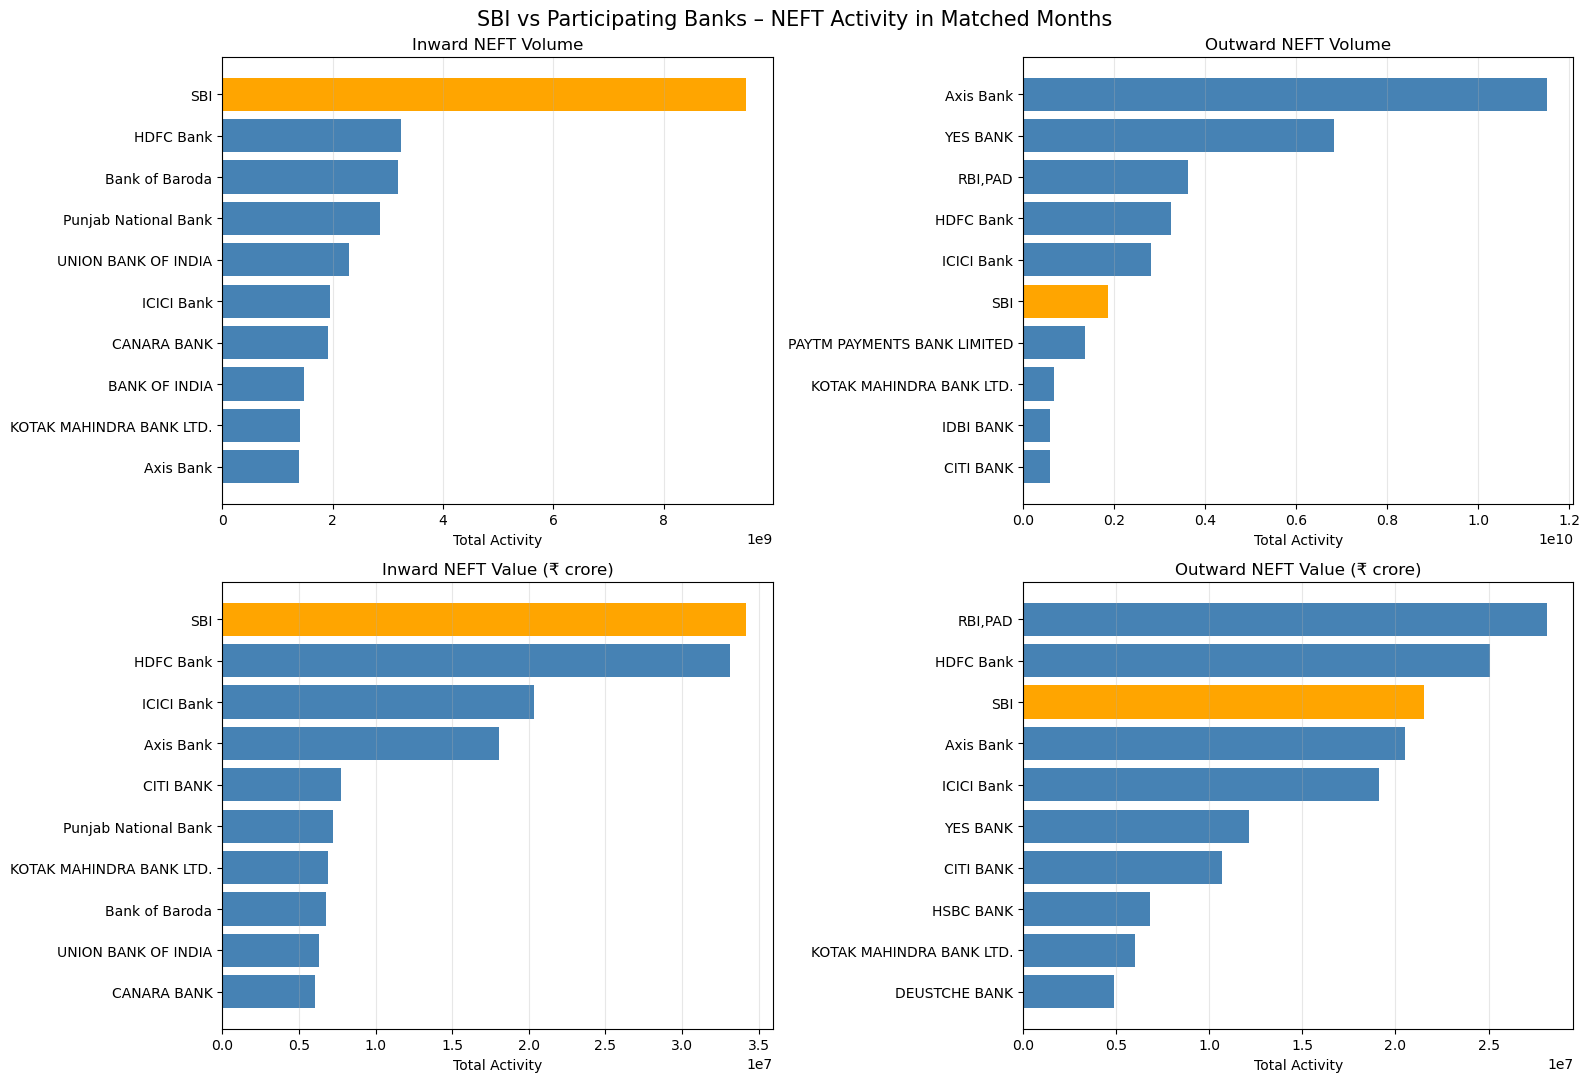

In [157]:
metrics = [
    ('Inward_Volume', 'Inward NEFT Volume'),
    ('Outward_Volume', 'Outward NEFT Volume'),
    ('Inward_Value', 'Inward NEFT Value (₹ crore)'),
    ('Outward_Value', 'Outward NEFT Value (₹ crore)')
]

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
axes = axes.flatten()

for ax, (column, title) in zip(axes, metrics):

    top_banks = neft_matched_summary.nlargest(10, column).copy()

    top_banks = top_banks.sort_values(column)

    bar_colors = [
        'orange' if bank == 'SBI' else 'steelblue'
        for bank in top_banks['Bank Name']
    ]

    ax.barh(
        top_banks['Bank Name'],
        top_banks[column],
        color=bar_colors
    )

    ax.set_title(title)
    ax.set_xlabel('Total Activity')
    ax.grid(axis='x', alpha=0.3)

plt.suptitle(
    'SBI vs Participating Banks – NEFT Activity in Matched Months',
    fontsize=15
)

plt.tight_layout()
plt.show()

### AQ-031 -- What same-month year-on-year changes are visible in NEFT inward and outward volume and value where matched observations exist?

In [160]:
# Select current-year NEFT observations
current_neft = df_neft[
    [
        'Bank Name',
        'Date',
        'Inward Volume',
        'Outward Volume',
        'Inward Amount (₹ crore)',
        'Outward Amount (₹ crore)'
    ]
].copy()

# Prepare previous-year observations
previous_neft = current_neft.copy()

previous_neft['Date'] = (
    previous_neft['Date'] + pd.DateOffset(years=1)
)

previous_neft = previous_neft.rename(columns={
    'Inward Volume': 'Previous_Inward_Volume',
    'Outward Volume': 'Previous_Outward_Volume',
    'Inward Amount (₹ crore)': 'Previous_Inward_Value',
    'Outward Amount (₹ crore)': 'Previous_Outward_Value'
})

# Match the same bank and calendar month across consecutive years
neft_yoy = current_neft.merge(
    previous_neft,
    on=['Bank Name', 'Date'],
    how='inner'
)

# Calculate year-on-year percentage changes
measures = {
    'Inward_Volume': ('Inward Volume', 'Previous_Inward_Volume'),
    'Outward_Volume': ('Outward Volume', 'Previous_Outward_Volume'),
    'Inward_Value': (
        'Inward Amount (₹ crore)', 'Previous_Inward_Value'
    ),
    'Outward_Value': (
        'Outward Amount (₹ crore)', 'Previous_Outward_Value'
    )
}

for name, (current, previous) in measures.items():
    neft_yoy[name + '_Growth_%'] = (
        (neft_yoy[current] - neft_yoy[previous])
        / neft_yoy[previous].replace(0, np.nan)
    ) * 100

# Bank-level summary
neft_yoy_summary = (
    neft_yoy.groupby('Bank Name')
    .agg(
        Matched_Months=('Date', 'nunique'),

        Current_Inward_Volume=('Inward Volume', 'sum'),
        Previous_Inward_Volume=('Previous_Inward_Volume', 'sum'),

        Current_Outward_Volume=('Outward Volume', 'sum'),
        Previous_Outward_Volume=('Previous_Outward_Volume', 'sum'),

        Current_Inward_Value=('Inward Amount (₹ crore)', 'sum'),
        Previous_Inward_Value=('Previous_Inward_Value', 'sum'),

        Current_Outward_Value=('Outward Amount (₹ crore)', 'sum'),
        Previous_Outward_Value=('Previous_Outward_Value', 'sum')
    )
    .reset_index()
)

# Calculate aggregate year-on-year percentage changes
summary_measures = {
    'Inward_Volume': ('Current_Inward_Volume', 'Previous_Inward_Volume'),
    'Outward_Volume': ('Current_Outward_Volume', 'Previous_Outward_Volume'),
    'Inward_Value': ('Current_Inward_Value', 'Previous_Inward_Value'),
    'Outward_Value': ('Current_Outward_Value', 'Previous_Outward_Value')
}

for name, (current, previous) in summary_measures.items():
    neft_yoy_summary[name + '_Growth_%'] = (
        (neft_yoy_summary[current] - neft_yoy_summary[previous])
        / neft_yoy_summary[previous].replace(0, np.nan)
    ) * 100

neft_yoy_summary = neft_yoy_summary.sort_values(
    'Current_Inward_Volume', ascending=False
)

neft_yoy_summary.round(2).head(10)

,Bank Name,Matched_Months,Current_Inward_Volume,Previous_Inward_Volume,Current_Outward_Volume,Previous_Outward_Volume,Current_Inward_Value,Previous_Inward_Value,Current_Outward_Value,Previous_Outward_Value,Inward_Volume_Growth_%,Outward_Volume_Growth_%,Inward_Value_Growth_%,Outward_Value_Growth_%
163,SBI,48,8406893304,6970001861,1533628693,1456881959,"28,954,904.51","25,533,354.56","17,936,984.27","16,084,059.42",20.62,5.27,13.40,11.52
33,Bank of Baroda,48,2878867435,2315045303,361009055,339370575,"5,759,528.20","5,018,938.06","3,072,784.88","2,866,356.33",24.35,6.38,14.76,7.20
70,HDFC Bank,48,2833896192,2429496023,2713380354,2493914090,"27,842,781.91","24,800,099.15","20,989,521.00","19,190,751.28",16.65,8.80,12.27,9.37
143,Punjab National Bank,48,2560707512,2087853661,363232480,357458845,"6,049,651.75","5,456,570.08","2,937,592.63","2,791,368.05",22.65,1.62,10.87,5.24
231,UNION BANK OF INDIA,48,2069076514,1669040987,299211068,294636332,"5,265,107.02","4,689,682.63","2,290,781.88","2,082,320.01",23.97,1.55,12.27,10.01
34,CANARA BANK,48,1727632819,1399827596,344777651,328362969,"5,040,768.79","4,573,352.40","1,832,887.48","1,696,636.25",23.42,5.00,10.22,8.03
74,ICICI Bank,48,1589289070,1533834701,2406929529,2152630045,"17,333,913.41","15,069,742.73","16,206,836.56","14,306,299.70",3.62,11.81,15.02,13.28
23,BANK OF INDIA,48,1322214493,1087185844,150632391,145825692,"2,821,440.77","2,599,279.37","1,059,612.75","1,017,866.47",21.62,3.30,8.55,4.10
110,KOTAK MAHINDRA BANK LTD.,48,1263906600,1024404957,576028779,529313294,"5,902,269.72","5,143,070.17","5,069,144.79","4,490,533.81",23.38,8.83,14.76,12.89
79,INDIAN BANK,48,1189881035,985498756,186142063,168781639,"2,864,296.10","2,547,926.24","1,549,505.27","1,421,662.54",20.74,10.29,12.42,8.99


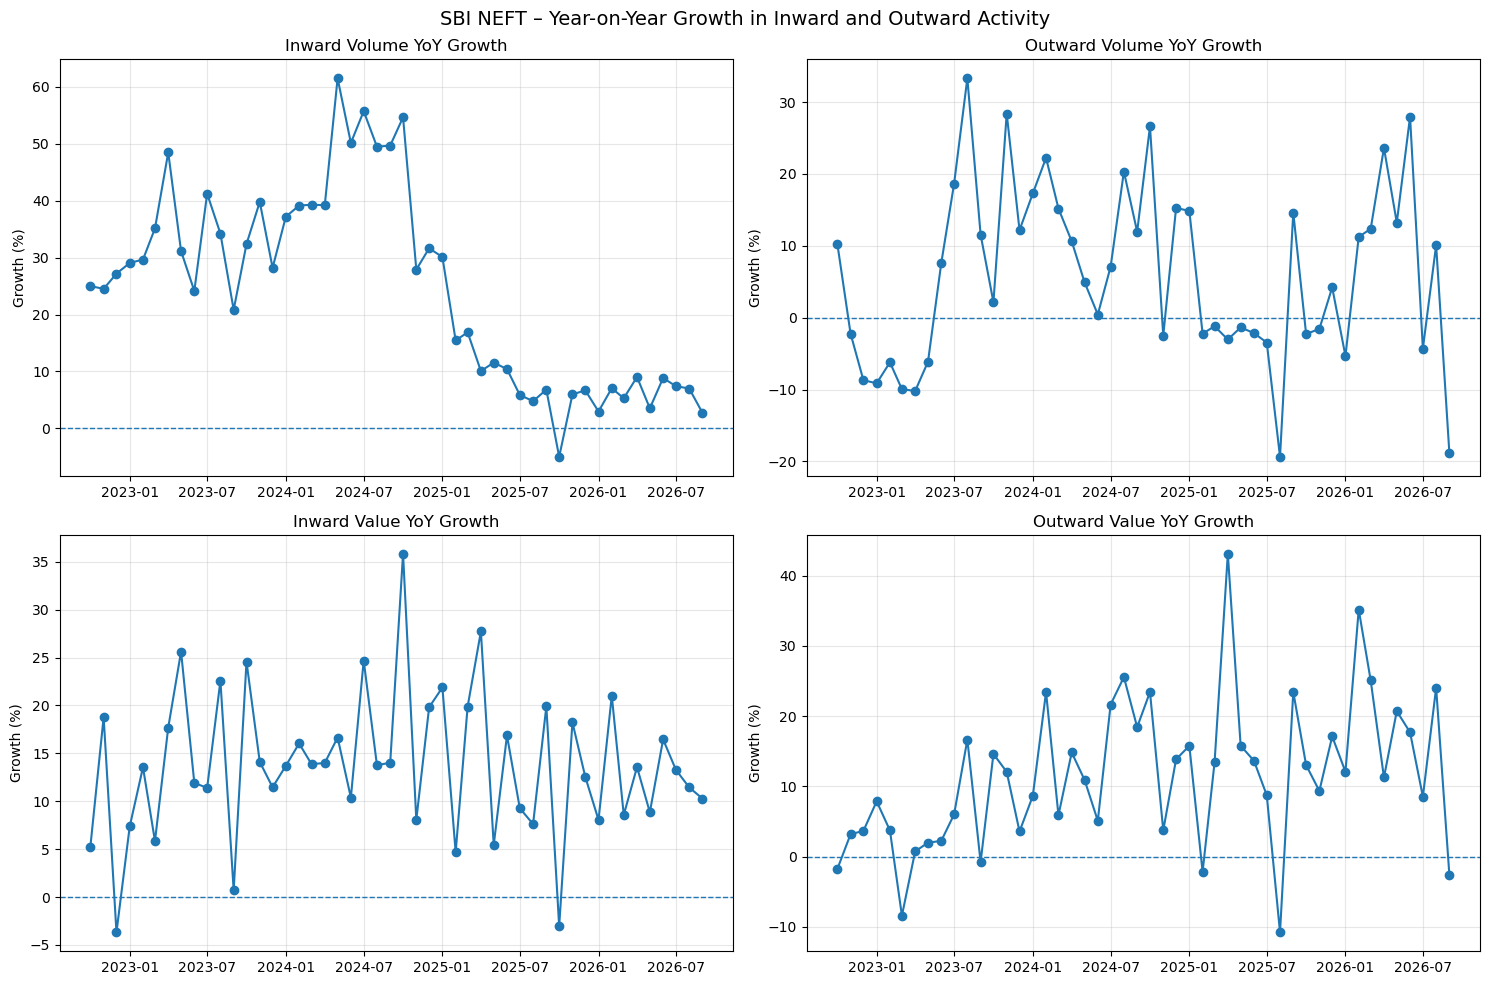

In [162]:
sbi_neft_yoy = neft_yoy[
    neft_yoy['Bank Name'] == 'SBI'
].sort_values('Date')

growth_columns = [
    ('Inward_Volume_Growth_%', 'Inward Volume YoY Growth'),
    ('Outward_Volume_Growth_%', 'Outward Volume YoY Growth'),
    ('Inward_Value_Growth_%', 'Inward Value YoY Growth'),
    ('Outward_Value_Growth_%', 'Outward Value YoY Growth')
]

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.flatten()

for ax, (column, title) in zip(axes, growth_columns):

    ax.plot(
        sbi_neft_yoy['Date'],
        sbi_neft_yoy[column],
        marker='o'
    )

    ax.axhline(0, linestyle='--', linewidth=1)
    ax.set_title(title)
    ax.set_ylabel('Growth (%)')
    ax.grid(True, alpha=0.3)

plt.suptitle(
    'SBI NEFT – Year-on-Year Growth in Inward and Outward Activity',
    fontsize=14
)

plt.tight_layout()
plt.show()

### AQ-032 -- What are the October–September annual inward and outward NEFT volume and value summaries by bank for complete periods?

In [164]:
# Create October–September reporting periods
df_neft['Period_Start_Year'] = np.where(
    df_neft['Month'] >= 10,
    df_neft['Year'],
    df_neft['Year'] - 1
)

df_neft['Period'] = (
    df_neft['Period_Start_Year'].astype(str)
    + '-'
    + (df_neft['Period_Start_Year'] + 1).astype(str)
)

# Annual summaries by bank
neft_annual = (
    df_neft.groupby(['Bank Name', 'Period', 'Period_Start_Year'])
    .agg(
        Inward_Volume=('Inward Volume', 'sum'),
        Outward_Volume=('Outward Volume', 'sum'),
        Inward_Value=('Inward Amount (₹ crore)', 'sum'),
        Outward_Value=('Outward Amount (₹ crore)', 'sum'),
        Observed_Months=('Date', 'nunique')
    )
    .reset_index()
)

# Keep only complete 12-month bank-periods
neft_annual_complete = neft_annual[
    neft_annual['Observed_Months'] == 12
].copy()

neft_annual_complete = neft_annual_complete.sort_values(
    ['Bank Name', 'Period_Start_Year']
)

neft_annual_complete.round(2).head(15)

,Bank Name,Period,Period_Start_Year,Inward_Volume,Outward_Volume,Inward_Value,Outward_Value,Observed_Months
0,ABHYUDAYA CO-OPERATIVE BANK LTD,2021-2022,2021,3758918,1628501,"11,502.21","5,028.03",12
1,ABHYUDAYA CO-OPERATIVE BANK LTD,2022-2023,2022,4621209,1561280,"11,713.67","5,090.64",12
2,ABHYUDAYA CO-OPERATIVE BANK LTD,2023-2024,2023,5371401,1401529,"11,207.78","5,019.24",12
3,ABHYUDAYA CO-OPERATIVE BANK LTD,2024-2025,2024,5220044,1318544,"10,906.53","5,082.54",12
4,ABHYUDAYA CO-OPERATIVE BANK LTD,2025-2026,2025,5008495,1300280,"11,247.13","5,540.52",12
5,AHMEDABAD MERCANTILE COOP BANK,2021-2022,2021,685201,467356,"4,792.04","4,900.49",12
6,AHMEDABAD MERCANTILE COOP BANK,2022-2023,2022,796350,494554,"5,173.46","5,197.88",12
7,AHMEDABAD MERCANTILE COOP BANK,2023-2024,2023,952154,547949,"5,422.15","6,020.76",12
8,AHMEDABAD MERCANTILE COOP BANK,2024-2025,2024,975137,585106,"5,475.98","6,827.01",12
9,AHMEDABAD MERCANTILE COOP BANK,2025-2026,2025,1025313,607567,"5,959.81","7,715.91",12


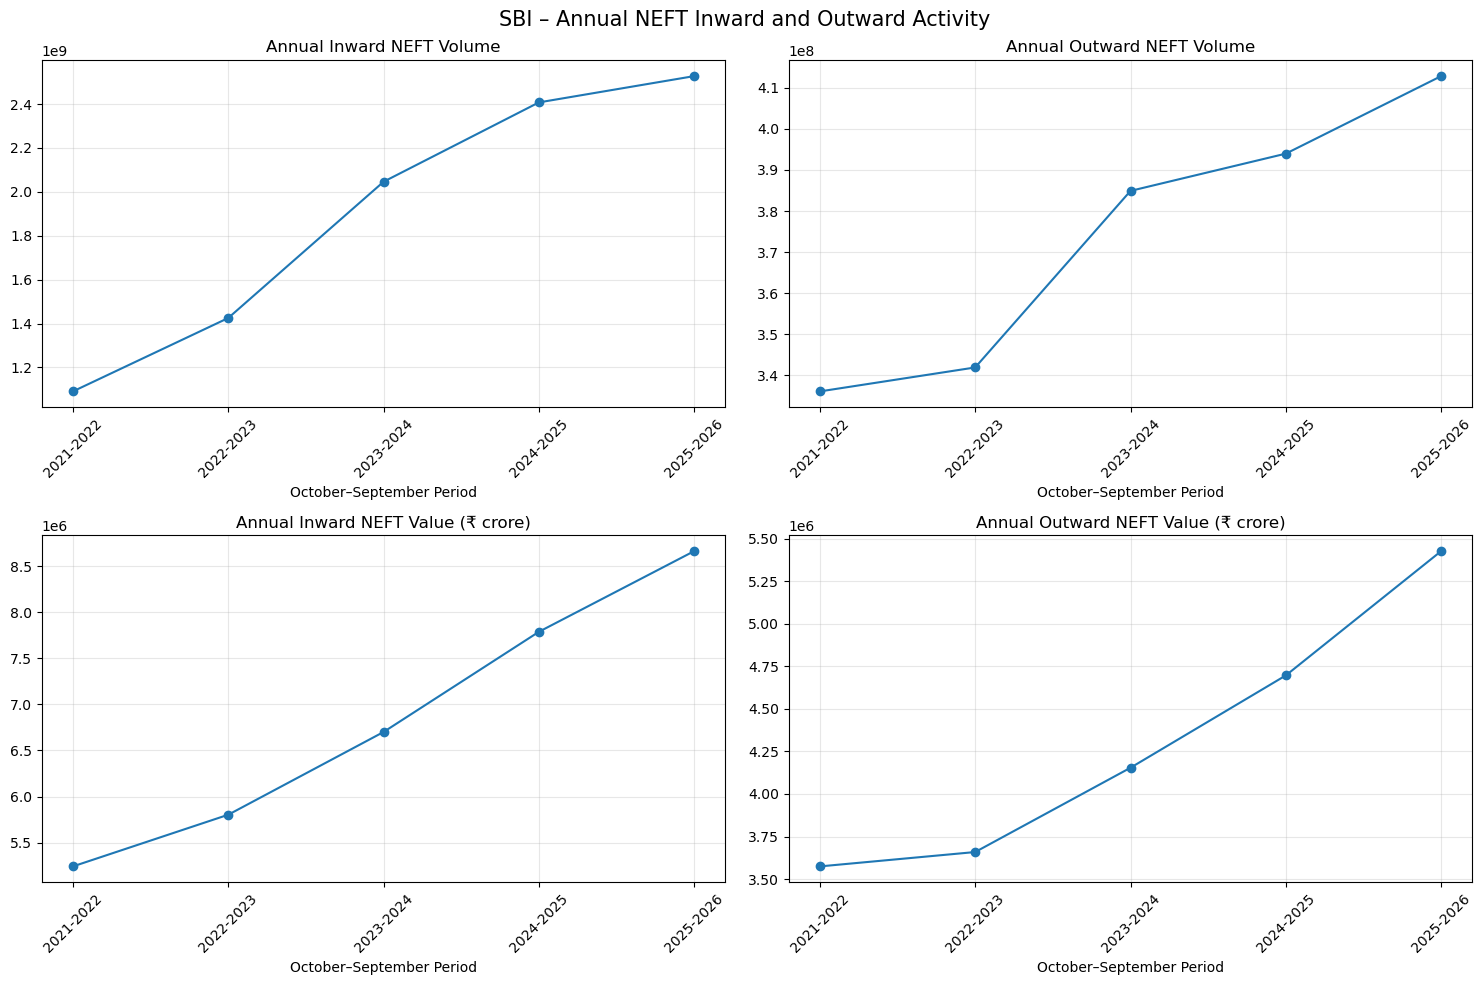

In [166]:
sbi_neft_annual = neft_annual_complete[
    neft_annual_complete['Bank Name'] == 'SBI'
].sort_values('Period_Start_Year')

metrics = [
    ('Inward_Volume', 'Annual Inward NEFT Volume'),
    ('Outward_Volume', 'Annual Outward NEFT Volume'),
    ('Inward_Value', 'Annual Inward NEFT Value (₹ crore)'),
    ('Outward_Value', 'Annual Outward NEFT Value (₹ crore)')
]

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.flatten()

for ax, (column, title) in zip(axes, metrics):

    ax.plot(
        sbi_neft_annual['Period'],
        sbi_neft_annual[column],
        marker='o'
    )

    ax.set_title(title)
    ax.set_xlabel('October–September Period')
    ax.grid(True, alpha=0.3)
    ax.tick_params(axis='x', rotation=45)

plt.suptitle(
    'SBI – Annual NEFT Inward and Outward Activity',
    fontsize=15
)

plt.tight_layout()
plt.show()

### AQ-033 -- How did monthly inward and outward RTGS total volumes change by bank?

In [199]:
df_rtgs['Date'] = pd.to_datetime(
    dict(year=df_rtgs['Year'], month=df_rtgs['Month'], day=1)
)

monthly_rtgs_volume = (
    df_rtgs.groupby(['Bank Name', 'Date'])
    .agg(
        Inward_Total_Volume=(
            'Inward Total Volume',
            lambda x: x.sum(min_count=1)
        ),
        Outward_Total_Volume=(
            'Outward Total Volume',
            lambda x: x.sum(min_count=1)
        )
    )
    .reset_index()
    .sort_values(['Bank Name', 'Date'])
)
rtgs_volume_summary = (
    monthly_rtgs_volume.groupby('Bank Name')
    .agg(
        Total_Inward_Volume=('Inward_Total_Volume', 'sum'),
        Total_Outward_Volume=('Outward_Total_Volume', 'sum'),
        Average_Inward_Volume=('Inward_Total_Volume', 'mean'),
        Average_Outward_Volume=('Outward_Total_Volume', 'mean'),
        Observed_Months=('Date', 'nunique')
    )
    .reset_index()
)

rtgs_volume_summary['Combined_Volume'] = (
    rtgs_volume_summary['Total_Inward_Volume']
    + rtgs_volume_summary['Total_Outward_Volume']
)

rtgs_volume_summary = rtgs_volume_summary.sort_values(
    'Combined_Volume', ascending=False
)

rtgs_volume_summary.round(2).head(10)

,Bank Name,Total_Inward_Volume,Total_Outward_Volume,Average_Inward_Volume,Average_Outward_Volume,Observed_Months,Combined_Volume
64,HDFC Bank,"282,186,302.00","261,377,846.00","4,703,105.03","4,356,297.43",60,"543,564,148.00"
151,SBI,"194,972,343.00","171,120,501.00","3,249,539.05","2,852,008.35",60,"366,092,844.00"
67,ICICI Bank,"178,123,581.00","165,409,288.00","2,968,726.35","2,756,821.47",60,"343,532,869.00"
13,Axis Bank,"118,341,269.00","112,968,322.00","1,972,354.48","1,882,805.37",60,"231,309,591.00"
103,KOTAK MAHINDRA BANK LTD.,"70,993,197.00","66,593,389.00","1,183,219.95","1,109,889.82",60,"137,586,586.00"
136,Punjab National Bank,"56,356,620.00","70,001,751.00","939,277.00","1,166,695.85",60,"126,358,371.00"
26,Bank of Baroda,"51,596,094.00","62,850,692.00","859,934.90","1,047,511.53",60,"114,446,786.00"
257,UNION BANK OF INDIA,"48,942,160.00","57,363,769.00","815,702.67","956,062.82",60,"106,305,929.00"
27,CANARA BANK,"41,021,465.00","50,436,036.00","683,691.08","840,600.60",60,"91,457,501.00"
268,YES BANK LTD,"35,295,177.00","44,578,220.00","588,252.95","742,970.33",60,"79,873,397.00"


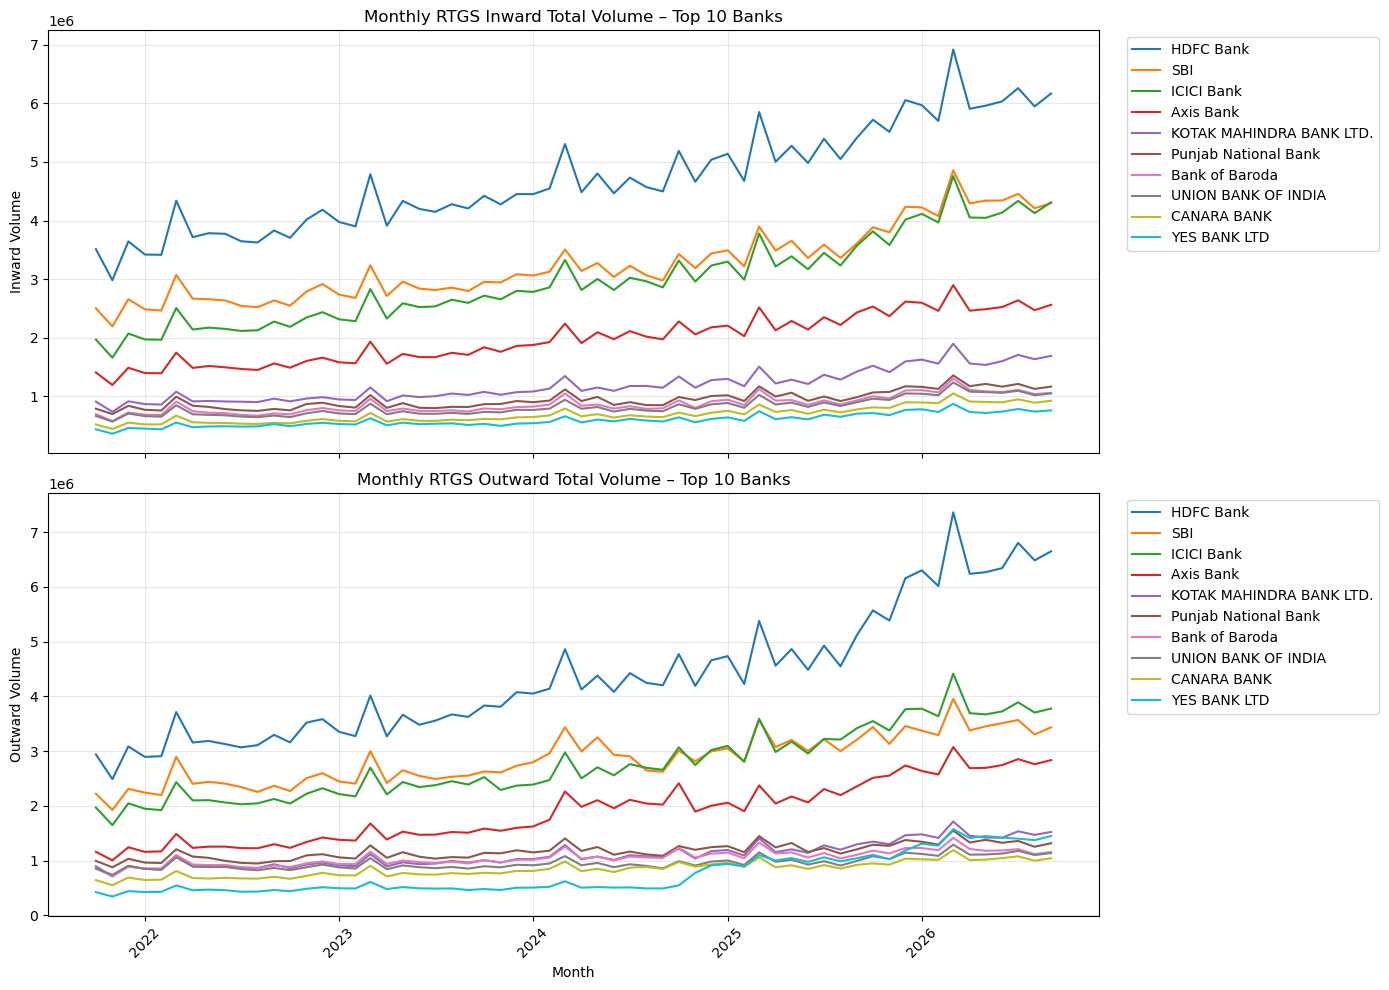

In [172]:
top_10_rtgs = rtgs_volume_summary.head(10)['Bank Name']

rtgs_top_banks = monthly_rtgs_volume[
    monthly_rtgs_volume['Bank Name'].isin(top_10_rtgs)
]

fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=True)

for bank in top_10_rtgs:

    bank_data = rtgs_top_banks[
        rtgs_top_banks['Bank Name'] == bank
    ]

    axes[0].plot(
        bank_data['Date'],
        bank_data['Inward_Total_Volume'],
        label=bank
    )

    axes[1].plot(
        bank_data['Date'],
        bank_data['Outward_Total_Volume'],
        label=bank
    )

axes[0].set_title('Monthly RTGS Inward Total Volume – Top 10 Banks')
axes[0].set_ylabel('Inward Volume')
axes[0].legend(bbox_to_anchor=(1.02, 1), loc='upper left')
axes[0].grid(True, alpha=0.3)

axes[1].set_title('Monthly RTGS Outward Total Volume – Top 10 Banks')
axes[1].set_xlabel('Month')
axes[1].set_ylabel('Outward Volume')
axes[1].legend(bbox_to_anchor=(1.02, 1), loc='upper left')
axes[1].grid(True, alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### AQ-34 -- How did monthly inward and outward RTGS total values change by bank?

In [201]:
monthly_rtgs_value = (
    df_rtgs.groupby(['Bank Name', 'Date'])
    .agg(
        Inward_Total_Value=(
            'Inward Total Amount (₹ crore)',
            lambda x: x.sum(min_count=1)
        ),
        Outward_Total_Value=(
            'Outward Total Amount (₹ crore)',
            lambda x: x.sum(min_count=1)
        )
    )
    .reset_index()
    .sort_values(['Bank Name', 'Date'])
)

rtgs_value_summary = (
    monthly_rtgs_value.groupby('Bank Name')
    .agg(
        Total_Inward_Value=('Inward_Total_Value', 'sum'),
        Total_Outward_Value=('Outward_Total_Value', 'sum'),
        Average_Inward_Value=('Inward_Total_Value', 'mean'),
        Average_Outward_Value=('Outward_Total_Value', 'mean'),
        Observed_Months=('Date', 'nunique')
    )
    .reset_index()
)

rtgs_value_summary['Combined_Value'] = (
    rtgs_value_summary['Total_Inward_Value']
    + rtgs_value_summary['Total_Outward_Value']
)

rtgs_value_summary = rtgs_value_summary.sort_values(
    'Combined_Value', ascending=False
)

rtgs_value_summary.round(2).head(10)

,Bank Name,Total_Inward_Value,Total_Outward_Value,Average_Inward_Value,Average_Outward_Value,Observed_Months,Combined_Value
64,HDFC Bank,"171,270,674.31","189,449,695.79","2,854,511.24","3,157,494.93",60,"360,720,370.10"
151,SBI,"110,291,000.39","117,520,464.64","1,838,183.34","1,958,674.41",60,"227,811,465.03"
67,ICICI Bank,"99,839,119.38","102,983,389.87","1,663,985.32","1,716,389.83",60,"202,822,509.26"
13,Axis Bank,"78,815,403.98","80,533,933.86","1,313,590.07","1,342,232.23",60,"159,349,337.84"
32,CITI BANK N.A.,"34,977,381.35","34,908,127.50","582,956.36","581,802.12",60,"69,885,508.85"
44,DEUTSCHE BANK AG,"29,073,706.61","27,535,669.99","484,561.78","458,927.83",60,"56,609,376.60"
167,STANDARD CHARTERED BANK,"24,246,592.58","25,815,558.71","404,109.88","430,259.31",60,"50,062,151.28"
103,KOTAK MAHINDRA BANK LTD.,"24,007,925.17","25,280,951.43","400,132.09","421,349.19",60,"49,288,876.60"
144,RESERVE BANK OF INDIA,"46,554,397.25",730.01,"775,906.62",22.12,60,"46,555,127.26"
194,THE CLEARING CORPORATION OF INDIA LTD.,"25,217,424.52","20,696,160.88","420,290.41","344,936.01",60,"45,913,585.40"


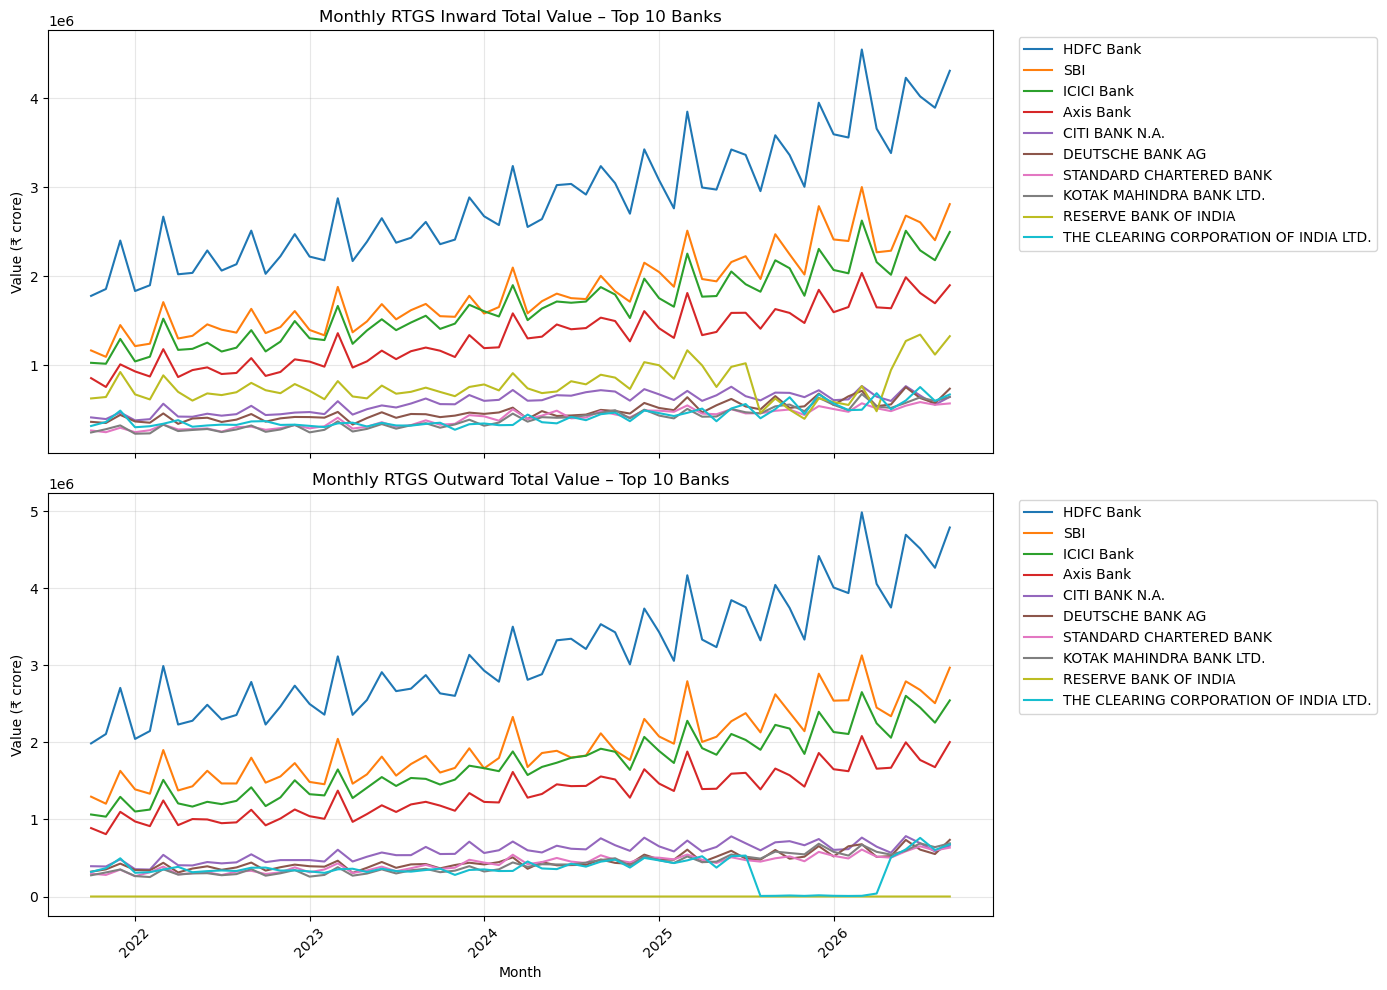

In [179]:
top_10_rtgs_value = rtgs_value_summary.head(10)['Bank Name']

rtgs_value_top_banks = monthly_rtgs_value[
    monthly_rtgs_value['Bank Name'].isin(top_10_rtgs_value)
]

fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=True)

for bank in top_10_rtgs_value:

    bank_data = rtgs_value_top_banks[
        rtgs_value_top_banks['Bank Name'] == bank
    ]

    axes[0].plot(
        bank_data['Date'],
        bank_data['Inward_Total_Value'],
        label=bank
    )

    axes[1].plot(
        bank_data['Date'],
        bank_data['Outward_Total_Value'],
        label=bank
    )

axes[0].set_title('Monthly RTGS Inward Total Value – Top 10 Banks')
axes[0].set_ylabel('Value (₹ crore)')
axes[0].legend(bbox_to_anchor=(1.02, 1), loc='upper left')
axes[0].grid(True, alpha=0.3)

axes[1].set_title('Monthly RTGS Outward Total Value – Top 10 Banks')
axes[1].set_xlabel('Month')
axes[1].set_ylabel('Value (₹ crore)')
axes[1].legend(bbox_to_anchor=(1.02, 1), loc='upper left')
axes[1].grid(True, alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### AQ-035 -- Where observed, how did RTGS inward and outward interbank and customer segment volumes and values change over time?

In [183]:
# Monthly RTGS segment analysis
rtgs_segments = [
    'Inward Interbank Volume',
    'Inward Customer Volume',
    'Inward Interbank Amount (₹ crore)',
    'Inward Customer Amount (₹ crore)',
    'Outward Interbank Volume',
    'Outward Customer Volume',
    'Outward Interbank Amount (₹ crore)',
    'Outward Customer Amount (₹ crore)'
]

monthly_rtgs_segments = (
    df_rtgs.groupby(['Bank Name', 'Date'])[rtgs_segments]
    .sum(min_count=1)
    .reset_index()
    .sort_values(['Bank Name', 'Date'])
)

# Summary by bank, preserving missing observations
rtgs_segment_summary = (
    monthly_rtgs_segments.groupby('Bank Name')[rtgs_segments]
    .agg(['mean', 'max', 'min'])
)

rtgs_segment_summary.head(10)

Inward Interbank Volume  \
                                                                     mean   
Bank Name                                                                   
ABHYUDAYA CO-OPERATIVE BANK LTD                                      9.73   
AHMEDNAGAR MERCHANT'S CO-OP. BANK LTD. AHMEDNAGAR                    1.47   
AIRTEL PAYMENTS BANK LTD.                                           13.98   
AKHAND ANAND CO-OPERATIVE BANK LTD                                   2.00   
ALMORA URBAN CO-OPERATIVE BANK LTD.                                  1.46   
AMBARNATH JAI-HIND CO-OP. BANK LTD.                                  1.60   
ANDHRA PRADESH GRAMEENA VIKAS BANK                                   4.14   
ANDHRA PRADESH STATE CO-OPERATIVE BANK LTD.                         51.95   
ANDHRA PRAGATHI GRAMEENA BANK                                       39.80   
APNA SAHAKARI BANK LTD.                                             46.88   

                                                                \
                                                     max   min   
Bank Name                                                        
ABHYUDAYA CO-OPERATIVE BANK LTD                    23.00  1.00   
AHMEDNAGAR MERCHANT'S CO-OP. BANK LTD. AHMEDNAGAR   4.00  1.00   
AIRTEL PAYMENTS BANK LTD.                          52.00  1.00   
AKHAND ANAND CO-OPERATIVE BANK LTD                  3.00  1.00   
ALMORA URBAN CO-OPERATIVE BANK LTD.                 5.00  1.00   
AMBARNATH JAI-HIND CO-OP. BANK LTD.                 4.00  1.00   
ANDHRA PRADESH GRAMEENA VIKAS BANK                 16.00  1.00   
ANDHRA PRADESH STATE CO-OPERATIVE BANK LTD.        84.00 24.00   
ANDHRA PRAGATHI GRAMEENA BANK                     116.00 11.00   
APNA SAHAKARI BANK LTD.                            83.00 27.00   

                                                  Inward Customer Volume  \
                                                                    mean   
Bank Name                                                                  
ABHYUDAYA CO-OPERATIVE BANK LTD                                 7,768.32   
AHMEDNAGAR MERCHANT'S CO-OP. BANK LTD. AHMEDNAGAR               4,048.53   
AIRTEL PAYMENTS BANK LTD.                                      31,091.98   
AKHAND ANAND CO-OPERATIVE BANK LTD                                172.17   
ALMORA URBAN CO-OPERATIVE BANK LTD.                             1,325.68   
AMBARNATH JAI-HIND CO-OP. BANK LTD.                               539.35   
ANDHRA PRADESH GRAMEENA VIKAS BANK                              3,618.41   
ANDHRA PRADESH STATE CO-OPERATIVE BANK LTD.                     3,440.15   
ANDHRA PRAGATHI GRAMEENA BANK                                   6,487.00   
APNA SAHAKARI BANK LTD.                                         2,846.03   

                                                                       \
                                                        max       min   
Bank Name                                                               
ABHYUDAYA CO-OPERATIVE BANK LTD                   10,935.00  6,160.00   
AHMEDNAGAR MERCHANT'S CO-OP. BANK LTD. AHMEDNAGAR  6,384.00  2,181.00   
AIRTEL PAYMENTS BANK LTD.                         38,582.00 24,434.00   
AKHAND ANAND CO-OPERATIVE BANK LTD                   274.00     29.00   
ALMORA URBAN CO-OPERATIVE BANK LTD.                2,072.00    779.00   
AMBARNATH JAI-HIND CO-OP. BANK LTD.                  756.00    361.00   
ANDHRA PRADESH GRAMEENA VIKAS BANK                 6,169.00    380.00   
ANDHRA PRADESH STATE CO-OPERATIVE BANK LTD.        7,883.00  1,819.00   
ANDHRA PRAGATHI GRAMEENA BANK                     11,519.00  2,799.00   
APNA SAHAKARI BANK LTD.                            3,992.00  2,277.00   

                                                  Inward Interbank Amount (₹ crore)  \
                                                                               mean   
Bank Name                                                                   

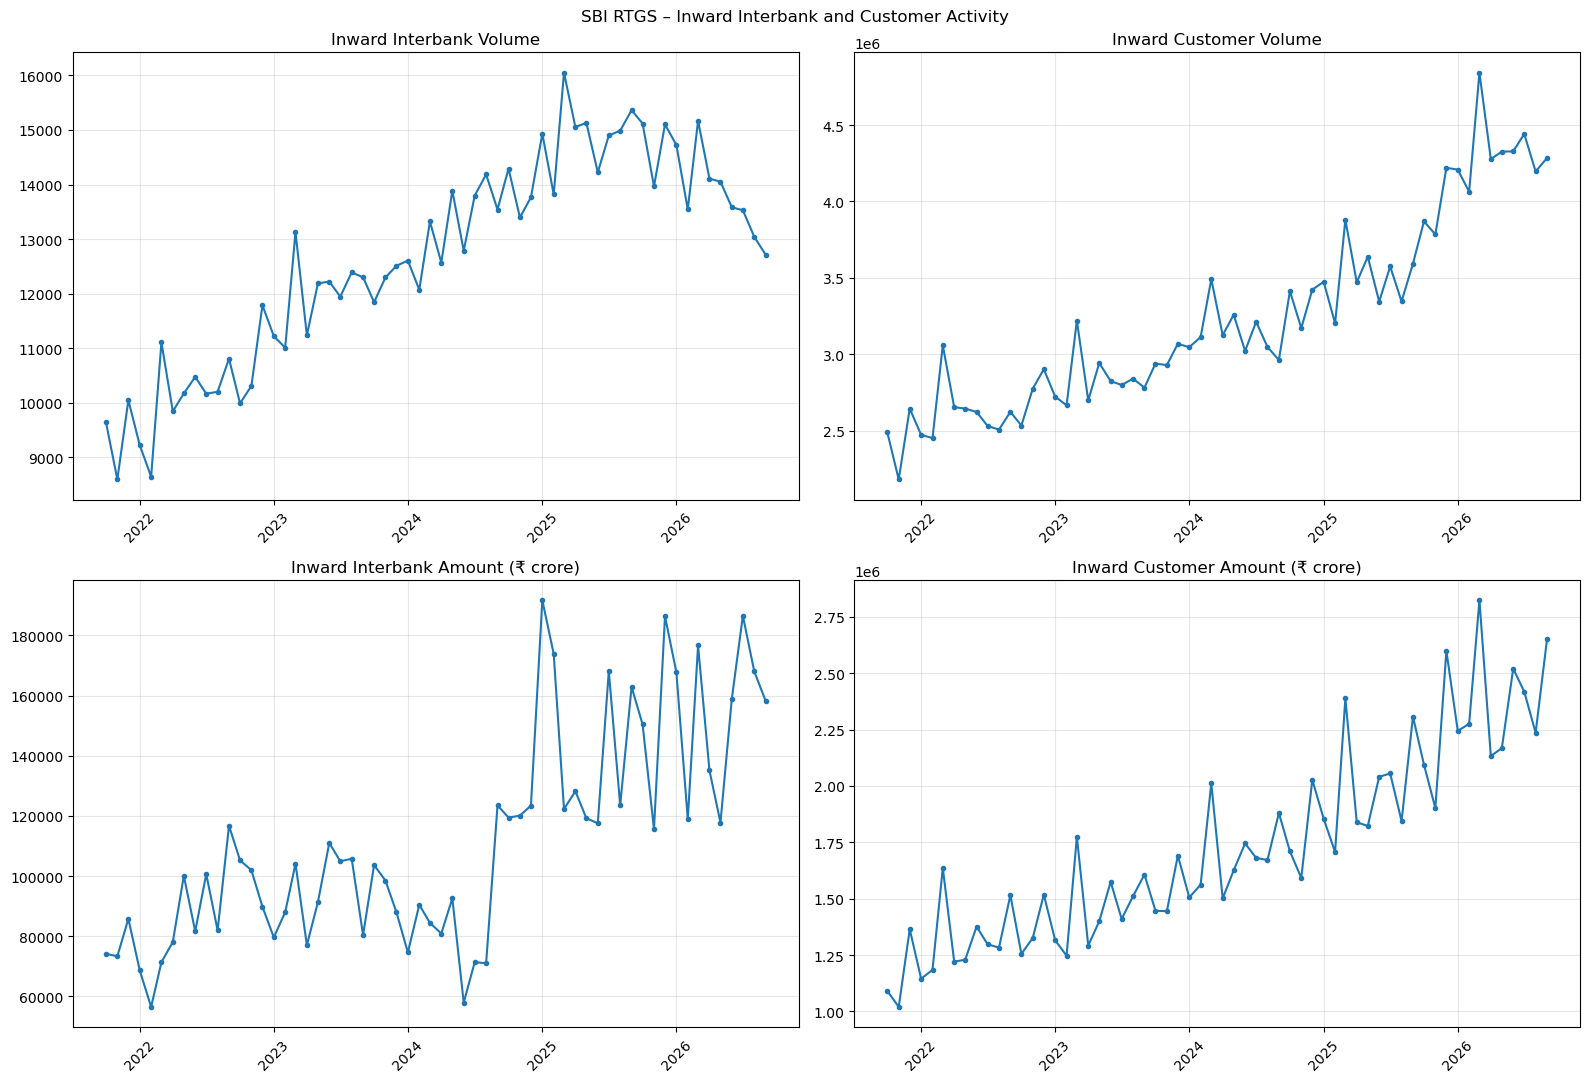

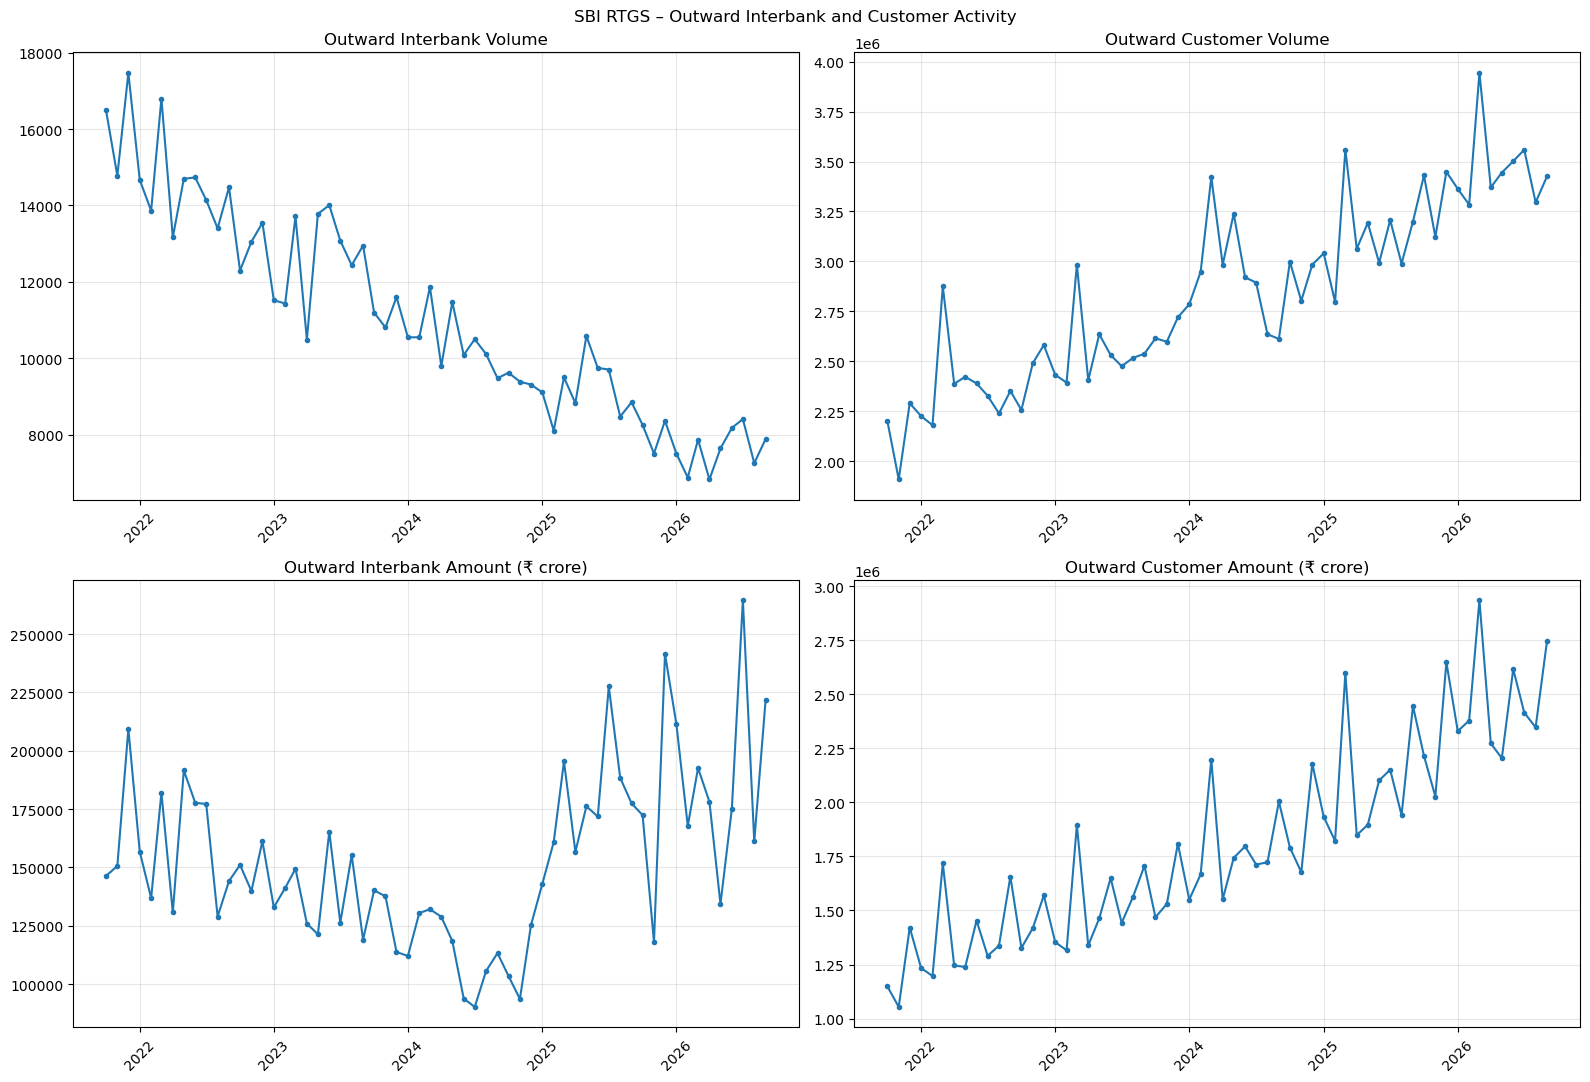

In [185]:
sbi_rtgs_segments = monthly_rtgs_segments[
    monthly_rtgs_segments['Bank Name'] == 'SBI'
].sort_values('Date')

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

charts = [
    ('Inward Interbank Volume', 'Inward Interbank Volume'),
    ('Inward Customer Volume', 'Inward Customer Volume'),
    ('Inward Interbank Amount (₹ crore)', 'Inward Interbank Amount (₹ crore)'),
    ('Inward Customer Amount (₹ crore)', 'Inward Customer Amount (₹ crore)')
]

for ax, (column, title) in zip(axes.flatten(), charts):
    ax.plot(
        sbi_rtgs_segments['Date'],
        sbi_rtgs_segments[column],
        marker='o',
        markersize=3
    )
    ax.set_title(title)
    ax.grid(True, alpha=0.3)
    ax.tick_params(axis='x', rotation=45)

plt.suptitle('SBI RTGS – Inward Interbank and Customer Activity')
plt.tight_layout()
plt.show()


fig, axes = plt.subplots(2, 2, figsize=(16, 11))

charts = [
    ('Outward Interbank Volume', 'Outward Interbank Volume'),
    ('Outward Customer Volume', 'Outward Customer Volume'),
    ('Outward Interbank Amount (₹ crore)', 'Outward Interbank Amount (₹ crore)'),
    ('Outward Customer Amount (₹ crore)', 'Outward Customer Amount (₹ crore)')
]

for ax, (column, title) in zip(axes.flatten(), charts):
    ax.plot(
        sbi_rtgs_segments['Date'],
        sbi_rtgs_segments[column],
        marker='o',
        markersize=3
    )
    ax.set_title(title)
    ax.grid(True, alpha=0.3)
    ax.tick_params(axis='x', rotation=45)

plt.suptitle('SBI RTGS – Outward Interbank and Customer Activity')
plt.tight_layout()
plt.show()

### AQ-036 -- Where reported, how did inward and outward RTGS volume shares and amount shares change by bank and month?

In [188]:
rtgs_share_columns = [
    'Inward Volume Share (%)',
    'Inward Amount Share (%)',
    'Outward Volume Share (%)',
    'Outward Amount Share (%)'
]

# Keep reported share observations only
monthly_rtgs_shares = (
    df_rtgs[
        ['Bank Name', 'Date'] + rtgs_share_columns
    ]
    .sort_values(['Bank Name', 'Date'])
    .copy()
)

# Summary of reported shares by bank
rtgs_share_summary = (
    monthly_rtgs_shares.groupby('Bank Name')[rtgs_share_columns]
    .agg(['mean', 'median', 'min', 'max', 'count'])
)

rtgs_share_summary.round(2).head(10)

Inward Volume Share (%)  \
                                                                     mean   
Bank Name                                                                   
ABHYUDAYA CO-OPERATIVE BANK LTD                                      0.03   
AHMEDNAGAR MERCHANT'S CO-OP. BANK LTD. AHMEDNAGAR                    0.02   
AIRTEL PAYMENTS BANK LTD.                                            0.13   
AKHAND ANAND CO-OPERATIVE BANK LTD                                   0.00   
ALMORA URBAN CO-OPERATIVE BANK LTD.                                  0.01   
AMBARNATH JAI-HIND CO-OP. BANK LTD.                                  0.00   
ANDHRA PRADESH GRAMEENA VIKAS BANK                                   0.02   
ANDHRA PRADESH STATE CO-OPERATIVE BANK LTD.                          0.01   
ANDHRA PRAGATHI GRAMEENA BANK                                        0.03   
APNA SAHAKARI BANK LTD.                                              0.01   

                                                                          \
                                                  median  min  max count   
Bank Name                                                                  
ABHYUDAYA CO-OPERATIVE BANK LTD                     0.03 0.02 0.05    60   
AHMEDNAGAR MERCHANT'S CO-OP. BANK LTD. AHMEDNAGAR   0.02 0.01 0.02    60   
AIRTEL PAYMENTS BANK LTD.                           0.14 0.09 0.16    60   
AKHAND ANAND CO-OPERATIVE BANK LTD                  0.00 0.00 0.00     6   
ALMORA URBAN CO-OPERATIVE BANK LTD.                 0.01 0.00 0.01    60   
AMBARNATH JAI-HIND CO-OP. BANK LTD.                 0.00 0.00 0.00    60   
ANDHRA PRADESH GRAMEENA VIKAS BANK                  0.02 0.00 0.03    49   
ANDHRA PRADESH STATE CO-OPERATIVE BANK LTD.         0.01 0.01 0.02    60   
ANDHRA PRAGATHI GRAMEENA BANK                       0.03 0.01 0.05    49   
APNA SAHAKARI BANK LTD.                             0.01 0.01 0.02    60   

                                                  Inward Amount Share (%)  \
                                                                     mean   
Bank Name                                                                   
ABHYUDAYA CO-OPERATIVE BANK LTD                                      0.01   
AHMEDNAGAR MERCHANT'S CO-OP. BANK LTD. AHMEDNAGAR                    0.00   
AIRTEL PAYMENTS BANK LTD.                                            0.05   
AKHAND ANAND CO-OPERATIVE BANK LTD                                   0.00   
ALMORA URBAN CO-OPERATIVE BANK LTD.                                  0.00   
AMBARNATH JAI-HIND CO-OP. BANK LTD.                                  0.00   
ANDHRA PRADESH GRAMEENA VIKAS BANK                                   0.03   
ANDHRA PRADESH STATE CO-OPERATIVE BANK LTD.                          0.06   
ANDHRA PRAGATHI GRAMEENA BANK                                        0.01   
APNA SAHAKARI BANK LTD.                                              0.01   

                                                                          \
                                                  median  min  max count   
Bank Name                                                                  
ABHYUDAYA CO-OPERATIVE BANK LTD                     0.01 0.00 0.01    60   
AHMEDNAGAR MERCHANT'S CO-OP. BANK LTD. AHMEDNAGAR   0.00 0.00 0.01    60   
AIRTEL PAYMENTS BANK LTD.                           0.05 0.03 0.08    60   
AKHAND ANAND CO-OPERATIVE BANK LTD                  0.00 0.00 0.00     6   
ALMORA URBAN CO-OPERATIVE BANK LTD.                 0.00 0.00 0.00    60   
AMBARNATH JAI-HIND CO-OP. BANK LTD.                 0.00 0.00 0.00    60   
ANDHRA PRADESH GRAMEENA VIKAS BANK                  0.04 0.00 0.08    49   
ANDHRA PRADESH STATE CO-OPERATIVE BANK LTD.         0.06 0.02 0.11    60   
ANDHRA PRAGATHI GRAMEENA BANK                       0.01 0.00 0.03    49   
APNA SAHAKARI BANK LTD.                             0.01 0.01 0.02    60   

                                                  Outward Volume Sha

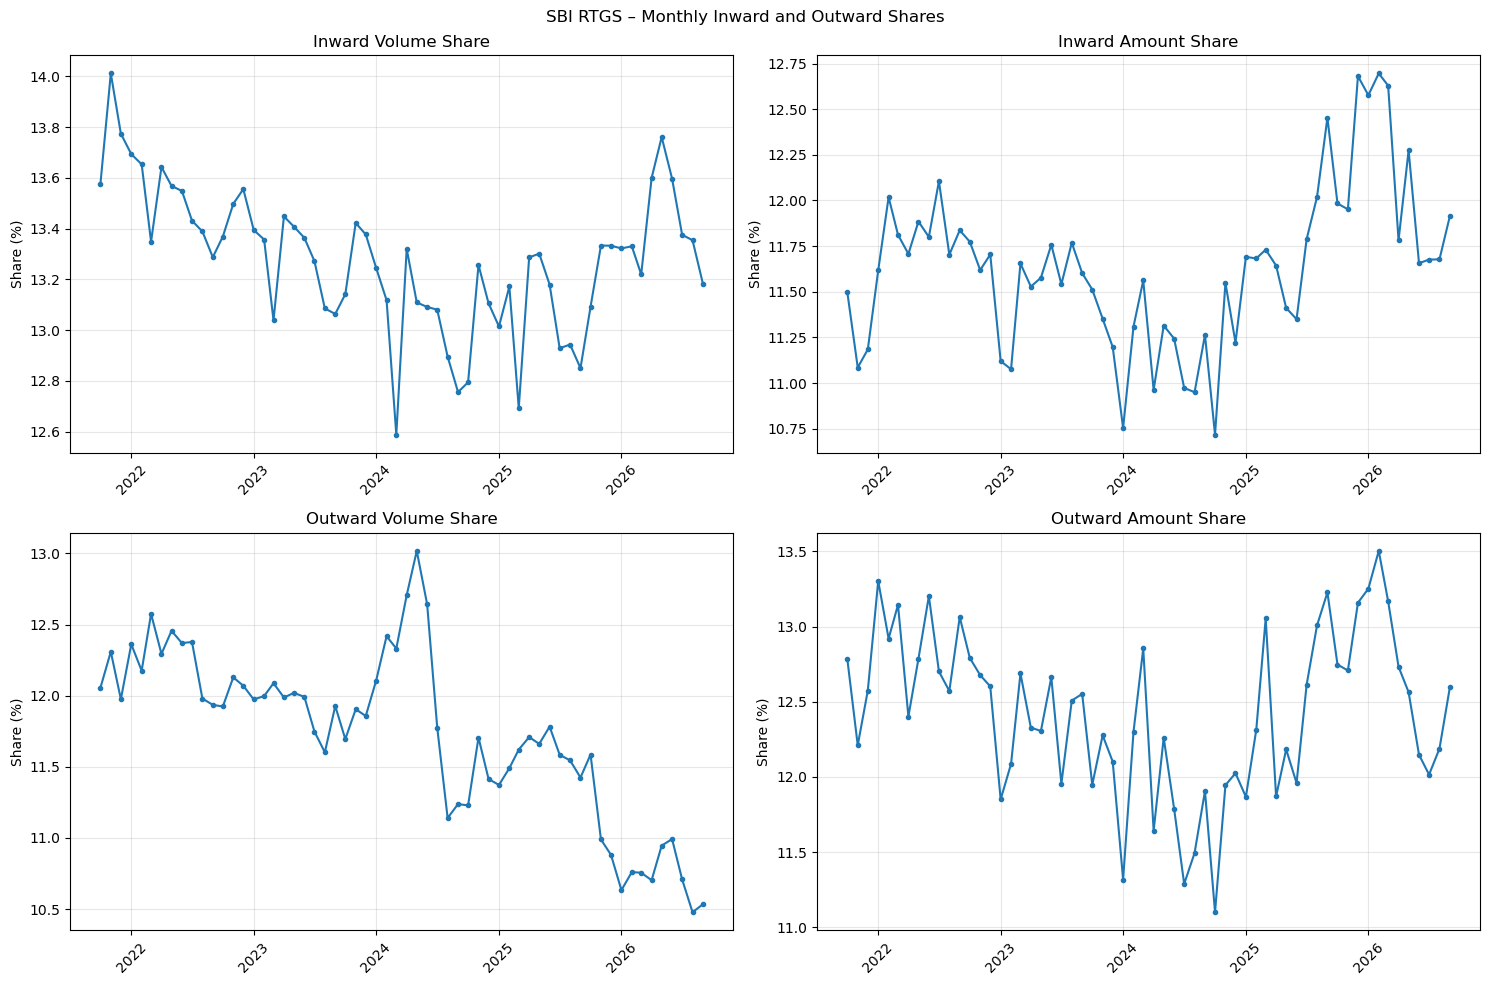

In [190]:
sbi_rtgs_shares = monthly_rtgs_shares[
    monthly_rtgs_shares['Bank Name'] == 'SBI'
].sort_values('Date')

share_charts = [
    ('Inward Volume Share (%)', 'Inward Volume Share'),
    ('Inward Amount Share (%)', 'Inward Amount Share'),
    ('Outward Volume Share (%)', 'Outward Volume Share'),
    ('Outward Amount Share (%)', 'Outward Amount Share')
]

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.flatten()

for ax, (column, title) in zip(axes, share_charts):

    ax.plot(
        sbi_rtgs_shares['Date'],
        sbi_rtgs_shares[column],
        marker='o',
        markersize=3
    )

    ax.set_title(title)
    ax.set_ylabel('Share (%)')
    ax.grid(True, alpha=0.3)
    ax.tick_params(axis='x', rotation=45)

plt.suptitle('SBI RTGS – Monthly Inward and Outward Shares')
plt.tight_layout()
plt.show()

### AQ-037 -- What are the October–September annual RTGS total volume and value summaries and year-on-year changes for bank-measures with adequate period coverage?

In [195]:
# Create October–September reporting periods
df_rtgs['Period_Start_Year'] = np.where(
    df_rtgs['Month'] >= 10,
    df_rtgs['Year'],
    df_rtgs['Year'] - 1
)

df_rtgs['Period'] = (
    df_rtgs['Period_Start_Year'].astype(str)
    + '-'
    + (df_rtgs['Period_Start_Year'] + 1).astype(str)
)

# RTGS total measures
rtgs_total_columns = [
    'Inward Total Volume',
    'Outward Total Volume',
    'Inward Total Amount (₹ crore)',
    'Outward Total Amount (₹ crore)'
]

# Aggregate each measure separately and preserve missing values
rtgs_annual = (
    df_rtgs.groupby(
        ['Bank Name', 'Period', 'Period_Start_Year']
    )[rtgs_total_columns]
    .sum(min_count=1)
    .reset_index()
)

# Measure-level monthly coverage
rtgs_coverage = (
    df_rtgs.groupby(
        ['Bank Name', 'Period', 'Period_Start_Year']
    )[rtgs_total_columns]
    .count()
    .reset_index()
)

rtgs_coverage = rtgs_coverage.rename(columns={
    col: col + '_Months'
    for col in rtgs_total_columns
})

rtgs_annual = rtgs_annual.merge(
    rtgs_coverage,
    on=['Bank Name', 'Period', 'Period_Start_Year']
)

# Calculate YoY only when the same bank-measure has 12 observed months
for column in rtgs_total_columns:

    coverage_column = column + '_Months'

    rtgs_annual.loc[
        rtgs_annual[coverage_column] != 12, column
    ] = np.nan

    rtgs_annual = rtgs_annual.sort_values(
        ['Bank Name', 'Period_Start_Year']
    )

    previous_value = (
        rtgs_annual.groupby('Bank Name')[column].shift(1)
    )

    previous_period = (
        rtgs_annual.groupby('Bank Name')['Period_Start_Year'].shift(1)
    )

    valid_comparison = (
        (rtgs_annual['Period_Start_Year'] - previous_period) == 1
    ) & (previous_value != 0)

    rtgs_annual[column + '_YoY_%'] = np.where(
        valid_comparison,
        (rtgs_annual[column] - previous_value)
        / previous_value * 100,
        np.nan
    )

rtgs_annual.round(2).head(15)

,Bank Name,Period,Period_Start_Year,Inward Total Volume,Outward Total Volume,Inward Total Amount (₹ crore),Outward Total Amount (₹ crore),Inward Total Volume_Months,Outward Total Volume_Months,Inward Total Amount (₹ crore)_Months,Outward Total Amount (₹ crore)_Months,Inward Total Volume_YoY_%,Outward Total Volume_YoY_%,Inward Total Amount (₹ crore)_YoY_%,Outward Total Amount (₹ crore)_YoY_%
0,ABHYUDAYA CO-OPERATIVE BANK LTD,2021-2022,2021,"99,668.00","161,723.00","12,467.67","16,248.50",12,12,12,12,NaN,NaN,NaN,NaN
1,ABHYUDAYA CO-OPERATIVE BANK LTD,2022-2023,2022,"95,088.00","160,593.00","12,315.22","15,038.06",12,12,12,12,-4.60,-0.70,-1.22,-7.45
2,ABHYUDAYA CO-OPERATIVE BANK LTD,2023-2024,2023,"89,633.00","160,277.00","10,924.74","14,894.28",12,12,12,12,-5.74,-0.20,-11.29,-0.96
3,ABHYUDAYA CO-OPERATIVE BANK LTD,2024-2025,2024,"87,460.00","137,914.00","10,744.81","13,803.69",12,12,12,12,-2.42,-13.95,-1.65,-7.32
4,ABHYUDAYA CO-OPERATIVE BANK LTD,2025-2026,2025,"94,834.00","131,405.00","11,439.68","13,548.76",12,12,12,12,8.43,-4.72,6.47,-1.85
5,AHMEDNAGAR MERCHANT'S CO-OP. BANK LTD. AHMEDNAGAR,2021-2022,2021,"33,285.00","84,148.00","6,482.34","7,415.50",12,12,12,12,NaN,NaN,NaN,NaN
6,AHMEDNAGAR MERCHANT'S CO-OP. BANK LTD. AHMEDNAGAR,2022-2023,2022,"40,413.00","89,899.00","7,158.98","7,961.16",12,12,12,12,21.42,6.83,10.44,7.36
7,AHMEDNAGAR MERCHANT'S CO-OP. BANK LTD. AHMEDNAGAR,2023-2024,2023,"47,748.00","95,808.00","8,071.19","8,626.88",12,12,12,12,18.15,6.57,12.74,8.36
8,AHMEDNAGAR MERCHANT'S CO-OP. BANK LTD. AHMEDNAGAR,2024-2025,2024,"56,593.00","100,067.00","8,323.52","9,653.06",12,12,12,12,18.52,4.45,3.13,11.90
9,AHMEDNAGAR MERCHANT'S CO-OP. BANK LTD. AHMEDNAGAR,2025-2026,2025,"64,926.00","106,333.00","9,238.57","10,650.30",12,12,12,12,14.72,6.26,10.99,10.33


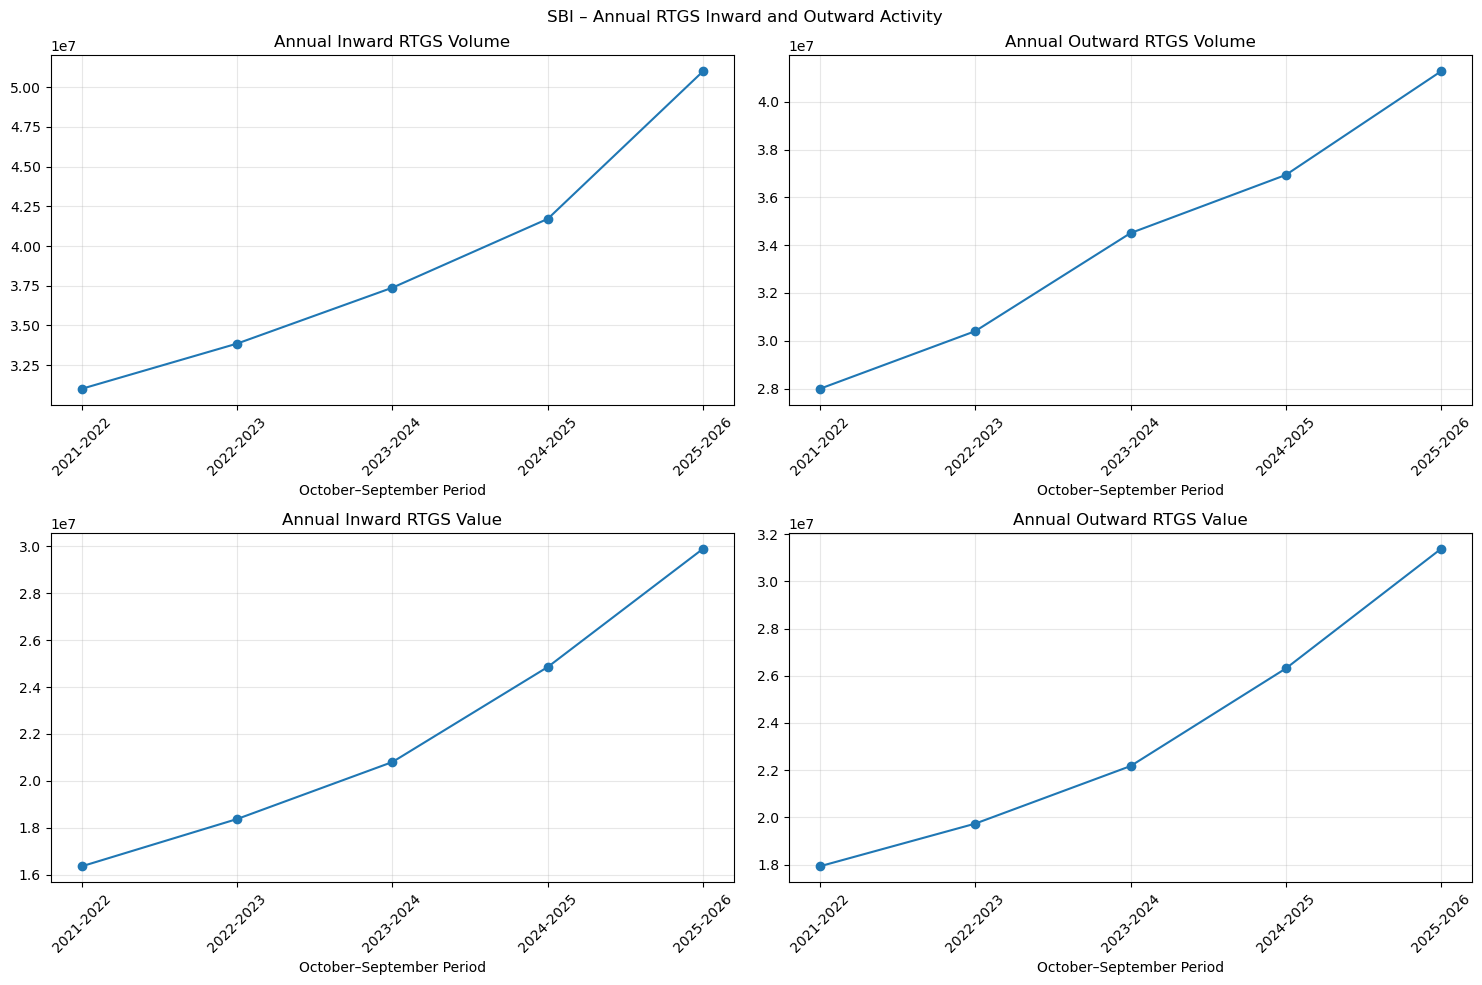

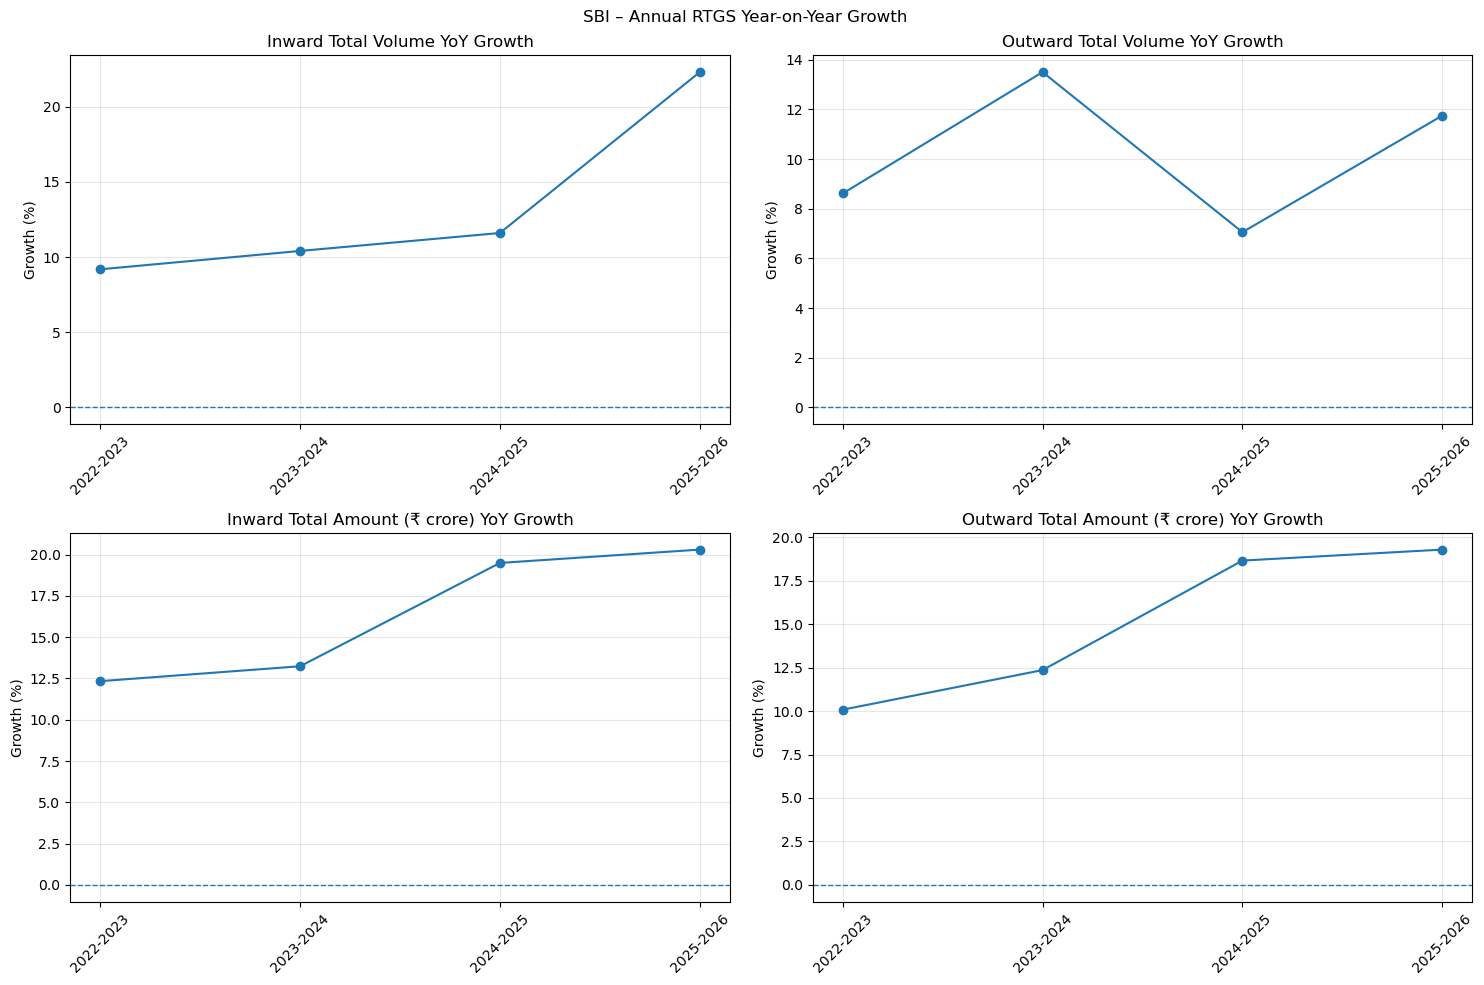

In [197]:
sbi_rtgs_annual = rtgs_annual[
    rtgs_annual['Bank Name'] == 'SBI'
].sort_values('Period_Start_Year')

metrics = [
    ('Inward Total Volume', 'Annual Inward RTGS Volume'),
    ('Outward Total Volume', 'Annual Outward RTGS Volume'),
    ('Inward Total Amount (₹ crore)', 'Annual Inward RTGS Value'),
    ('Outward Total Amount (₹ crore)', 'Annual Outward RTGS Value')
]

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.flatten()

for ax, (column, title) in zip(axes, metrics):

    ax.plot(
        sbi_rtgs_annual['Period'],
        sbi_rtgs_annual[column],
        marker='o'
    )

    ax.set_title(title)
    ax.set_xlabel('October–September Period')
    ax.grid(True, alpha=0.3)
    ax.tick_params(axis='x', rotation=45)

plt.suptitle('SBI – Annual RTGS Inward and Outward Activity')
plt.tight_layout()
plt.show()


# Year-on-year growth visualization
growth_columns = [
    (col + '_YoY_%', col + ' YoY Growth')
    for col, _ in metrics
]

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.flatten()

for ax, (column, title) in zip(axes, growth_columns):

    ax.plot(
        sbi_rtgs_annual['Period'],
        sbi_rtgs_annual[column],
        marker='o'
    )

    ax.axhline(0, linestyle='--', linewidth=1)
    ax.set_title(title)
    ax.set_ylabel('Growth (%)')
    ax.grid(True, alpha=0.3)
    ax.tick_params(axis='x', rotation=45)

plt.suptitle('SBI – Annual RTGS Year-on-Year Growth')
plt.tight_layout()
plt.show()